# Data Quality — Home Credit Application Data

This notebook audits the Home Credit application table before that table is used to train and evaluate the default-risk models. The source file is `data.csv`: 307,511 applications and 122 fields. `TARGET = 1` means the client had a repayment difficulty. `TARGET = 0` means the client did not.

The audit has four parts.

1. How often each field is missing. Null cells are missing, and so are the not-employed codes `DAYS_EMPLOYED = 365243` and `ORGANIZATION_TYPE = "XNA"`.
2. Whether missingness in the fields kept for modeling lines up with gender, age, income, or default, and whether the numeric fields are consistent with missing completely at random.
3. Where the existing outlier caps fall, who sits above them, and whether applications above a cap default at a different rate.
4. Whether gender, age, and income have similar shares, and similar default rates, in the training, validation, and test sets.

No model is trained in this notebook. The caps and the train/validation/test split are the ones already used to fit the saved XGBoost and MLP models. Wherever a modeling sample is required, two kinds of rows are removed first: `CODE_GENDER = XNA` and `NAME_FAMILY_STATUS = Unknown`. That leaves 307,505 applications.


In [301]:
from pathlib import Path

import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 160
plt.rcParams["savefig.dpi"] = 160
import pandas as pd

DATA_PATH = Path("data.csv")
OUTPUT_DIR = Path("output") / "data_quality"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected the application data at {DATA_PATH.resolve()}.")

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} applications and {df.shape[1]} fields.")


Loaded 307,511 applications and 122 fields.


## 1. Overall Missingness Profiling

This section counts missing values in the raw file. The two exclusion rules have not been applied, so all 307,511 applications stay in the denominator. A cell counts as missing when it is null in `data.csv`. `DAYS_EMPLOYED = 365243` and `ORGANIZATION_TYPE = "XNA"` are also counted as missing. Those codes mark applicants who are not employed, and Section 2 uses the same rule.

For every field with at least one missing value,

$$
\text{missing proportion} = \frac{\text{number of missing rows}}{307{,}511}.
$$

The table reports the count and the proportion, sorted from the most missing field to the least missing field. The bar chart shows the same proportions on a 0% to 100% scale. Fields that are fully observed are omitted. Sixty-nine fields have at least one missing value. The building-average fields are missing on the same applications and sit together near the top of the chart.

`DAYS_EMPLOYED` and `ORGANIZATION_TYPE` each contribute 55,374 missing values, which is 18.0% of applications. Both fields appear in the table and the bar chart.


In [302]:
missingness_frame = df.copy()
missingness_frame["DAYS_EMPLOYED"] = missingness_frame["DAYS_EMPLOYED"].replace(365243, pd.NA)
missingness_frame["ORGANIZATION_TYPE"] = missingness_frame["ORGANIZATION_TYPE"].replace("XNA", pd.NA)

missingness = pd.DataFrame({
    "missing": missingness_frame.isna().sum(),
    "missing_proportion": missingness_frame.isna().mean(),
})
missingness = (
    missingness[missingness["missing"].gt(0)]
    .sort_values(["missing_proportion", "missing"], ascending=False)
)
missingness.index.name = "column"

assert len(missingness) == 69
assert int(missingness.loc["DAYS_EMPLOYED", "missing"]) == 55374
assert int(missingness.loc["ORGANIZATION_TYPE", "missing"]) == 55374
display(missingness)
missingness.to_csv(OUTPUT_DIR / "missingness_by_field.csv")
print(f"{len(missingness)} fields have at least one missing value.")


,missing,missing_proportion
column,,
COMMONAREA_AVG,214865,0.698723
COMMONAREA_MODE,214865,0.698723
COMMONAREA_MEDI,214865,0.698723
NONLIVINGAPARTMENTS_AVG,213514,0.694330
NONLIVINGAPARTMENTS_MODE,213514,0.694330
NONLIVINGAPARTMENTS_MEDI,213514,0.694330
FONDKAPREMONT_MODE,210295,0.683862
LIVINGAPARTMENTS_AVG,210199,0.683550
LIVINGAPARTMENTS_MODE,210199,0.683550


69 fields have at least one missing value.


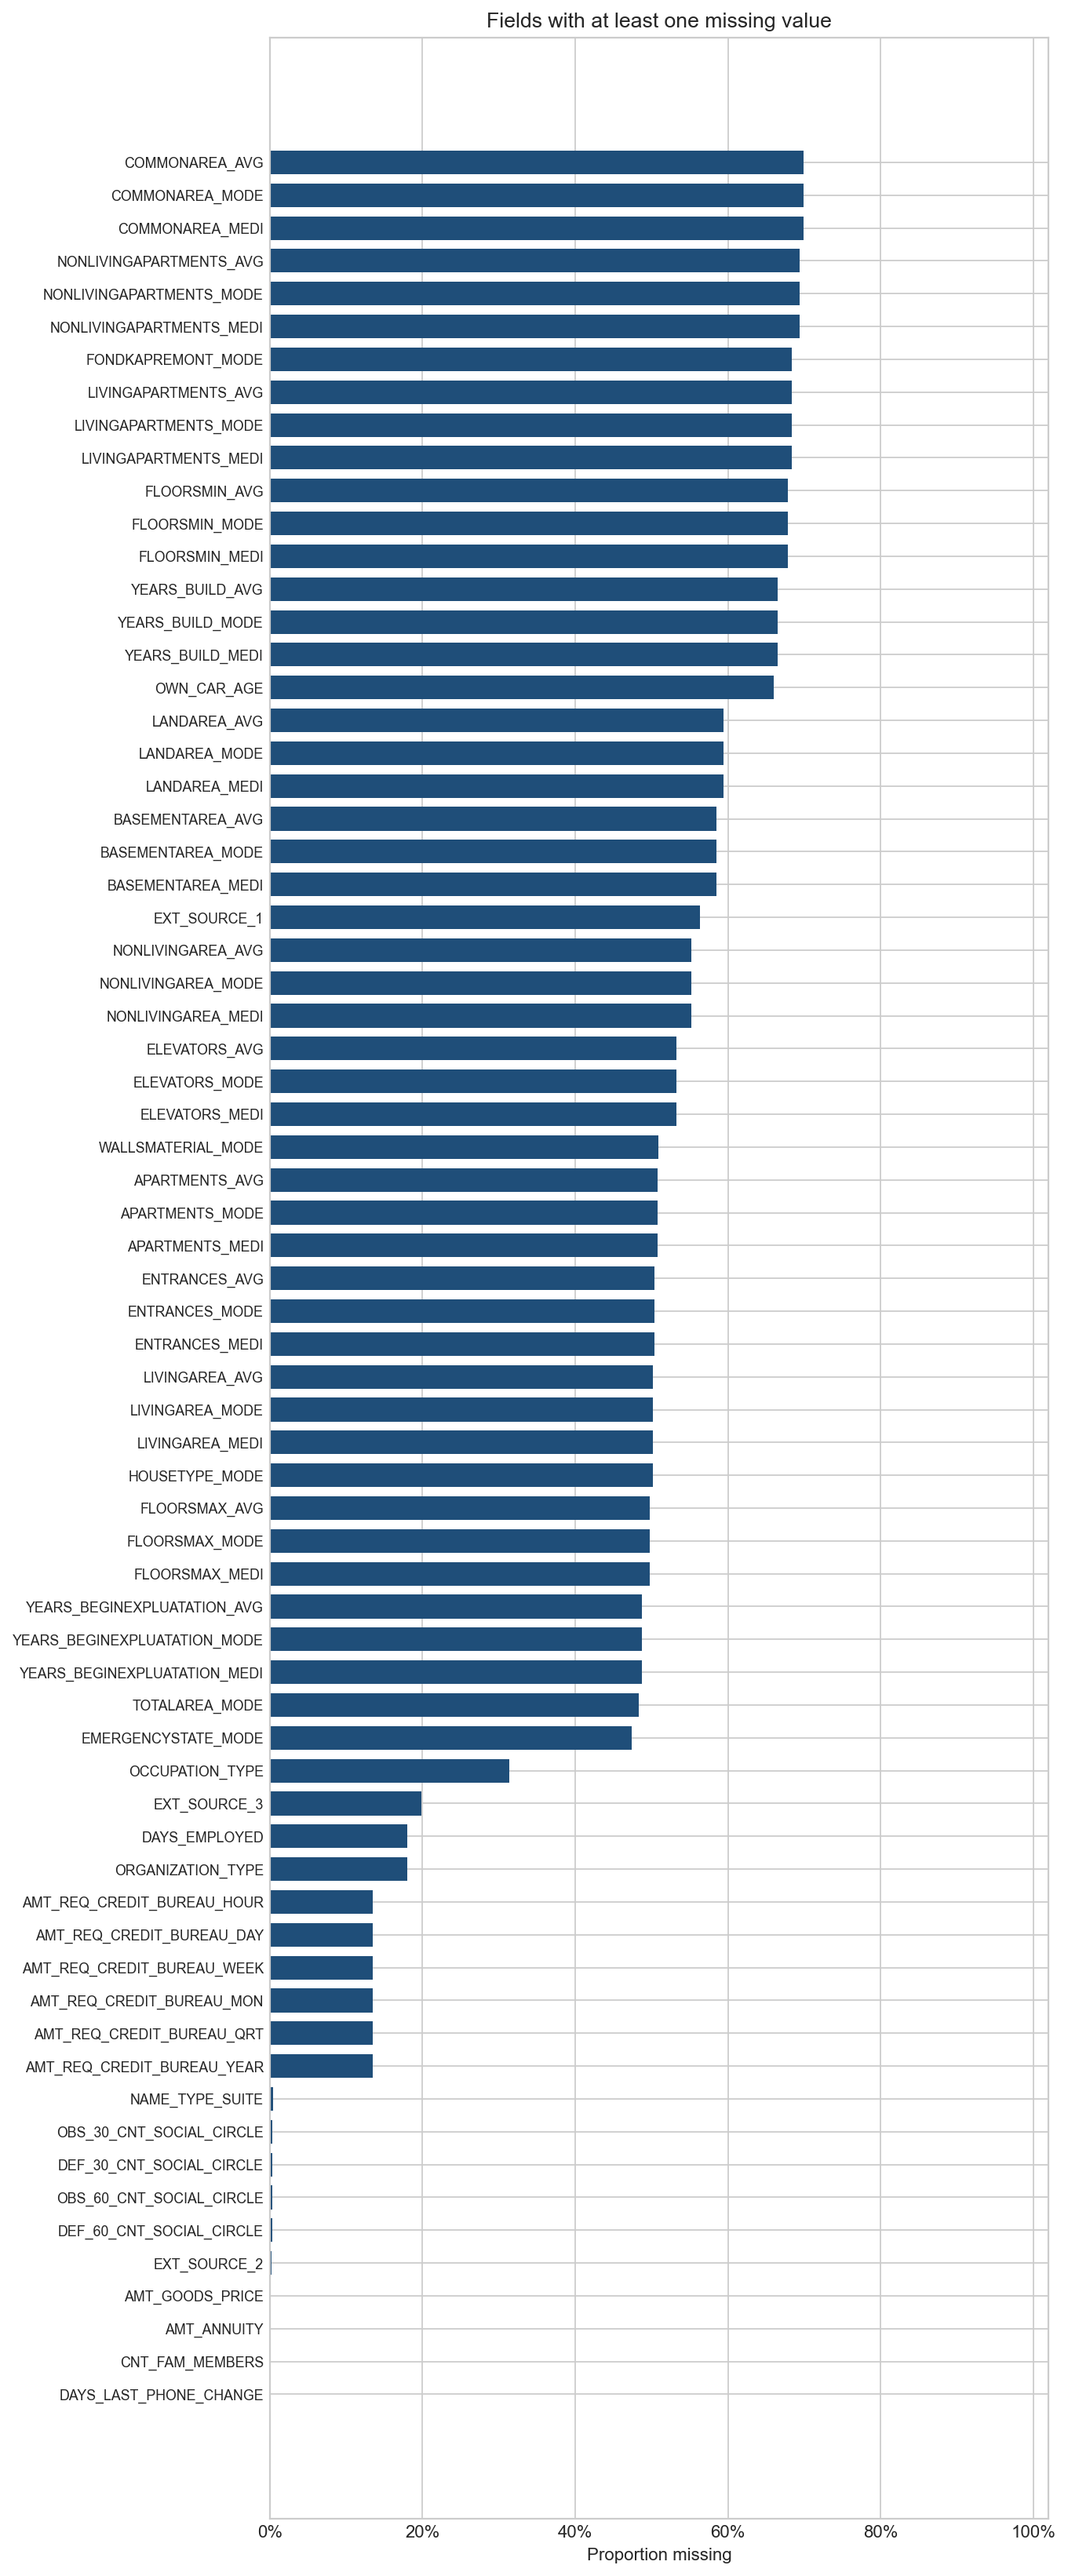

In [303]:
import numpy as np

figure_dir = OUTPUT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
labels = missingness.index.astype(str).tolist()
values = missingness["missing_proportion"].to_numpy()
positions = np.arange(len(labels))
figure, axis = plt.subplots(figsize=(8.6, 0.28 * len(labels) + 1.3))
axis.barh(positions, values, color="#1f4e79", height=0.72)
axis.set_yticks(positions, labels, fontsize=8)
axis.invert_yaxis()
axis.set_xlim(0, 1.02)
axis.set_xlabel("Proportion missing")
axis.set_title("Fields with at least one missing value")
axis.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _position: f"{value:.0%}"))
figure.tight_layout()
figure.savefig(figure_dir / "missingness_by_field.png", dpi=160, bbox_inches="tight")
plt.show()


## 2. Missingness Pattern and Mechanism

Section 1 says how often each field is missing. This section asks whether that missingness is spread evenly across applicants.

The analysis sample drops applications with `CODE_GENDER = XNA` or `NAME_FAMILY_STATUS = Unknown`. Age in years is $-\texttt{DAYS\_BIRTH}/365.25$. Gender is labeled Female or Male. Age bands use the same cuts as the rest of this audit. Income bands in this section are quartiles of `AMT_INCOME_TOTAL` on the analysis sample. Section 4 uses a different income cut: quartiles fit on the training set only.

Twenty-one fields are kept because they enter the model and are either missing or stored with a sentinel. Section 1 already counts `DAYS_EMPLOYED = 365243` and `ORGANIZATION_TYPE = "XNA"` as missing. This section applies that same rule to the analysis sample before any rate or test. Those codes mark applicants who are not employed. Leaving them as recorded would treat a status flag as a length of employment or as an employer name. All 55,374 of those applicants remain after the six exclusions, so the missing counts for these two fields match Section 1. The rates differ only because the denominator here is 307,505 rather than 307,511.

The three subsections answer different questions. Section 2.1 shows the missing rate inside each group. Section 2.2 tests whether missingness is associated with gender, age, income, and default. Section 2.3 tests whether a numeric subset is consistent with missing completely at random.

### 2.1 Missing Rate by Gender, Age Band, Income, and Default

For each retained field and each level of a grouping, the missing rate is the share of applications in that level whose value is missing:

$$
\text{missing rate}(\text{field}, \text{level})
= \frac{\text{number missing in the level}}{\text{number of applications in the level}}.
$$

Each table reports the number missing, the overall rate on the analysis sample, and the rate in every level. The heatmap uses those level rates. The color scale runs from 0 to 1 on every chart, so a dark cell is a high missing rate and a pale cell is a low one. Read across a row to compare levels of the grouping. Read down a column to see which fields are missing most often in that level.


In [304]:
import numpy as np

RETAINED_MISSING = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "OCCUPATION_TYPE", "NAME_TYPE_SUITE",
    "AMT_REQ_CREDIT_BUREAU_HOUR", "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK", "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR",
    "OBS_30_CNT_SOCIAL_CIRCLE", "DEF_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE", "DEF_60_CNT_SOCIAL_CIRCLE",
    "AMT_GOODS_PRICE", "AMT_ANNUITY", "CNT_FAM_MEMBERS",
    "DAYS_LAST_PHONE_CHANGE", "DAYS_EMPLOYED", "ORGANIZATION_TYPE",
]
AGE_BANDS = ["<25", "25–34", "35–44", "45–54", "55–64", "65+"]
GENDERS = ["Female", "Male"]
INCOME_BANDS = ["Q1 low", "Q2", "Q3", "Q4 high"]
DEFAULT_GROUPS = ["Non-default", "Default"]

missing_retained = [column for column in RETAINED_MISSING if column not in df.columns]
if missing_retained:
    raise ValueError(f"Missing retained fields: {missing_retained}")

analysis = df.loc[
    ~df["CODE_GENDER"].eq("XNA") & ~df["NAME_FAMILY_STATUS"].eq("Unknown")
].copy()
analysis["gender"] = analysis["CODE_GENDER"].map({"F": "Female", "M": "Male"})
analysis["age_years"] = -analysis["DAYS_BIRTH"] / 365.25
analysis["age_band"] = pd.cut(
    analysis["age_years"],
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=AGE_BANDS,
    right=False,
).astype("string")
income_quartiles = analysis["AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75]).to_numpy()
analysis["income_band"] = pd.cut(
    analysis["AMT_INCOME_TOTAL"],
    bins=[-np.inf, *income_quartiles, np.inf],
    labels=INCOME_BANDS,
    include_lowest=True,
).astype("string")
analysis["default_status"] = analysis["TARGET"].map({0: "Non-default", 1: "Default"})
analysis["DAYS_EMPLOYED"] = analysis["DAYS_EMPLOYED"].replace(365243, np.nan)
analysis["ORGANIZATION_TYPE"] = analysis["ORGANIZATION_TYPE"].replace("XNA", np.nan)

overall_rate = analysis[RETAINED_MISSING].isna().mean().rename("overall").rename_axis("column").reset_index()
retained_missing = (
    overall_rate.sort_values(["overall", "column"], ascending=[False, True])["column"].tolist()
)

def show_group_rates(title, group_name, levels):
    rows = []
    for feature in retained_missing:
        missing = analysis[feature].isna()
        row = {"n_missing": int(missing.sum()), "overall": float(missing.mean())}
        for level in levels:
            row[level] = float(missing[analysis[group_name].eq(level)].mean())
        rows.append(row)
    table = pd.DataFrame(rows, index=retained_missing)
    table.index.name = "column"
    display(table)

    slug = title.lower().replace(" ", "_")
    table.to_csv(OUTPUT_DIR / f"missingness_rates_by_{slug}.csv")

    rate_matrix = table[list(levels)]
    fig, ax = plt.subplots(figsize=(max(7, 1.15 * len(levels) + 4), 8))
    image = ax.imshow(rate_matrix.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    rotation = 0 if len(levels) <= 4 else 30
    ax.set_xticks(range(len(levels)))
    ax.set_xticklabels(list(levels), rotation=rotation, ha="center" if rotation == 0 else "right")
    ax.set_yticks(range(len(rate_matrix)))
    ax.set_yticklabels(rate_matrix.index)
    ax.set_title(f"Missing rate by {title.lower()}")
    for row_index, feature in enumerate(rate_matrix.index):
        for column_index, level in enumerate(levels):
            value = rate_matrix.loc[feature, level]
            ax.text(
                column_index,
                row_index,
                f"{value:.1%}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value >= 0.45 else "black",
            )
    fig.colorbar(image, ax=ax, label="Proportion missing")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"missingness_rates_by_{slug}.png", dpi=160, bbox_inches="tight")
    plt.show()

#### Gender

The two levels are Female and Male. The `XNA` gender rows are already out of the sample. A later test summarizes this comparison as Male minus Female, so a higher rate in the Male column is a positive gender gap in Section 2.2.


,n_missing,overall,Female,Male
column,,,,
EXT_SOURCE_1,173375,0.563812,0.547338,0.595557
OCCUPATION_TYPE,96389,0.313455,0.361408,0.221049
EXT_SOURCE_3,60964,0.198254,0.190731,0.212749
DAYS_EMPLOYED,55374,0.180075,0.223619,0.096166
ORGANIZATION_TYPE,55374,0.180075,0.223619,0.096166
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.129338,0.145957
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.129338,0.145957
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.129338,0.145957
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.129338,0.145957


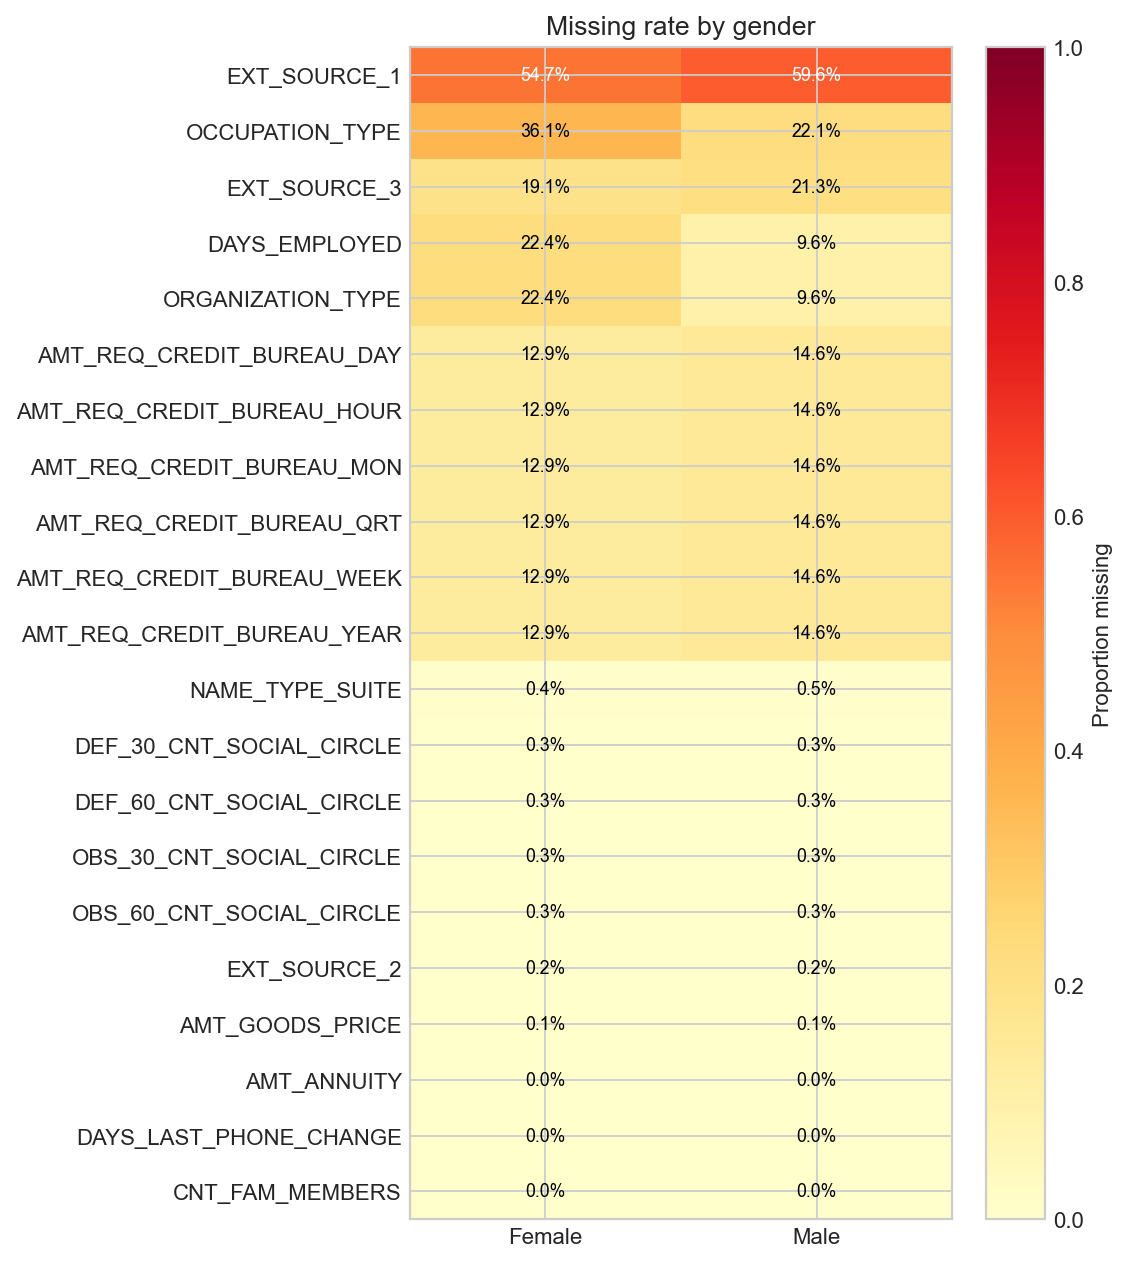

In [305]:
show_group_rates("Gender", "gender", GENDERS)

#### Age band

The bands are under 25, 25–34, 35–44, 45–54, 55–64, and 65+. The cuts fall at 25, 35, 45, 55, and 65 years, and the upper edge of each band is open. Employment and occupation fields are missing much more often at older ages, because the not-employed sentinel was recoded to missing. That pattern is visible in the heatmap before it is tested.


,n_missing,overall,<25,25–34,35–44,45–54,55–64,65+
column,,,,,,,,
EXT_SOURCE_1,173375,0.563812,0.448459,0.411109,0.490630,0.632968,0.754598,0.847765
OCCUPATION_TYPE,96389,0.313455,0.175100,0.167205,0.165680,0.229776,0.739677,0.924708
EXT_SOURCE_3,60964,0.198254,0.344642,0.215185,0.178070,0.188674,0.183969,0.226257
DAYS_EMPLOYED,55374,0.180075,0.002779,0.003659,0.011607,0.079157,0.684985,0.899568
ORGANIZATION_TYPE,55374,0.180075,0.002779,0.003659,0.011607,0.079157,0.684985,0.899568
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093


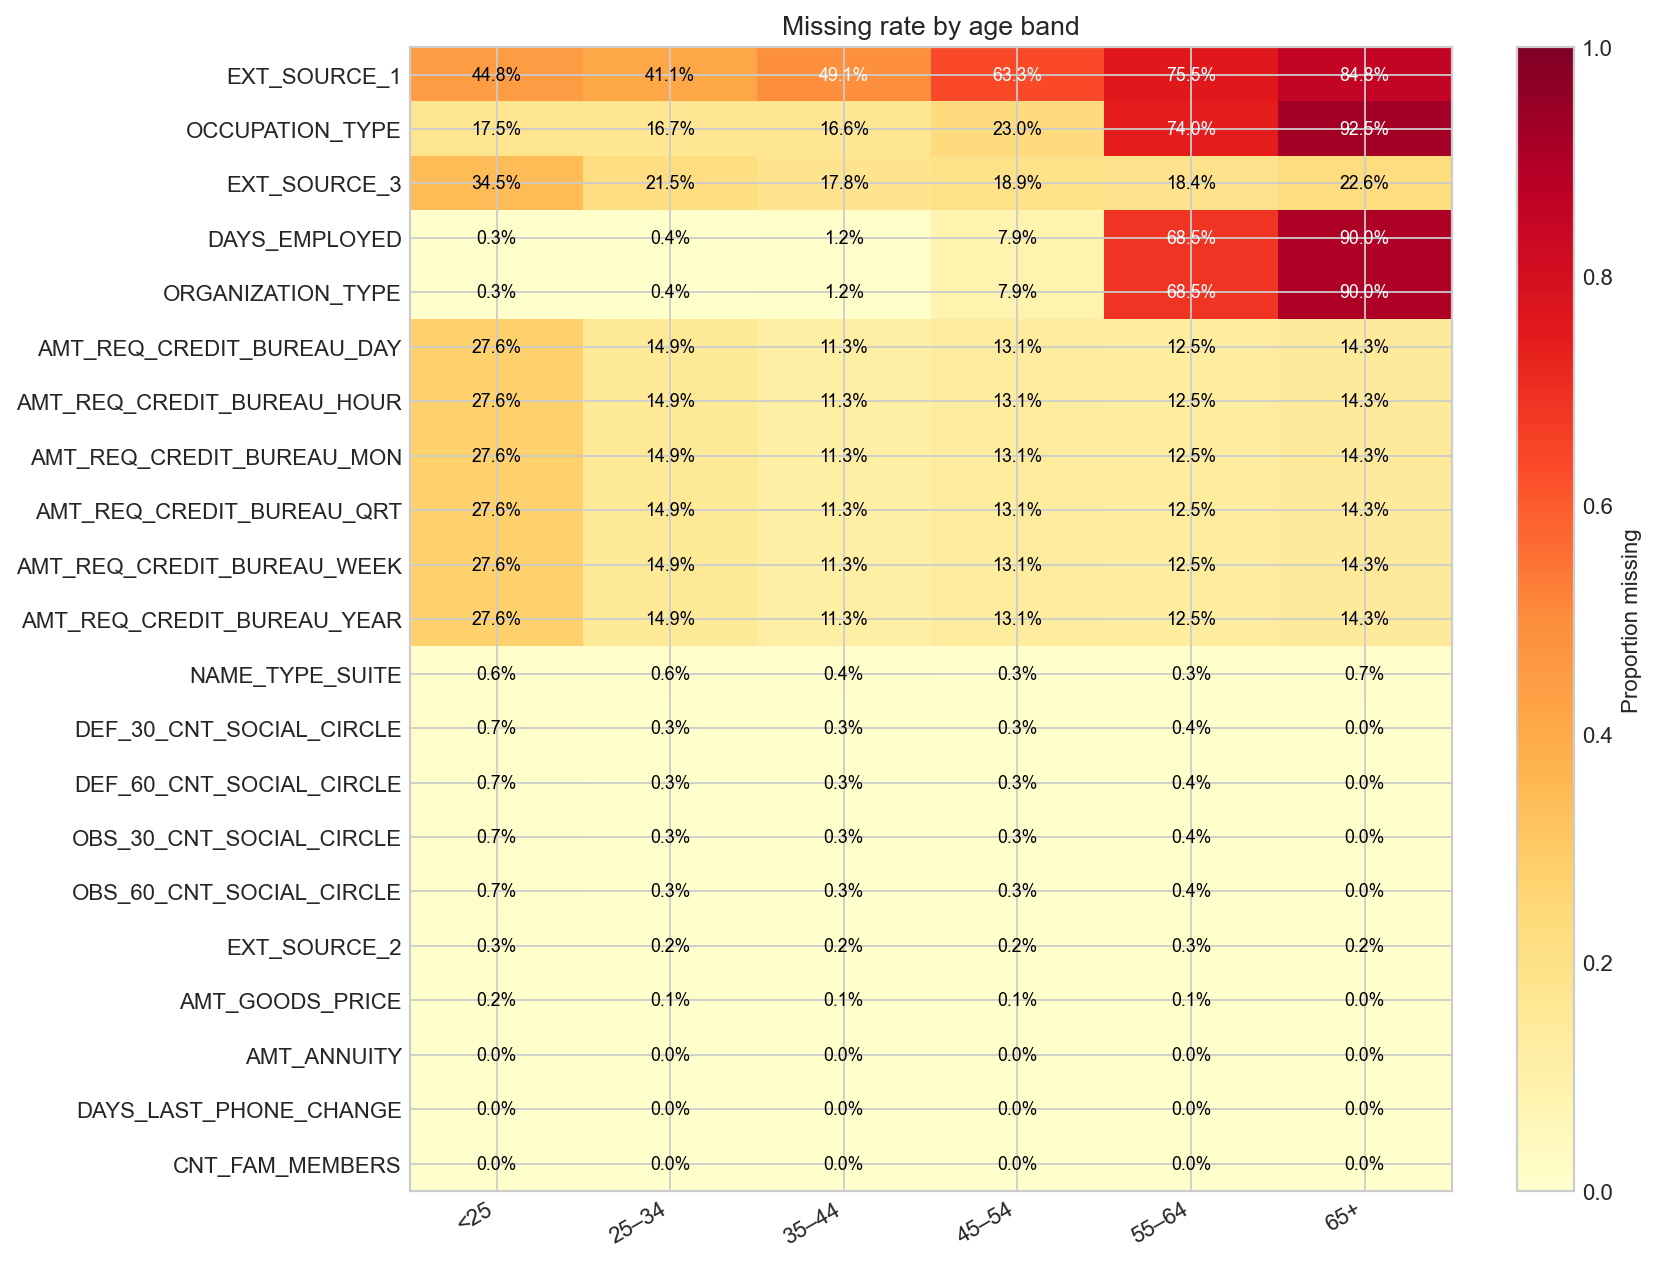

In [306]:
show_group_rates("Age band", "age_band", AGE_BANDS)

#### Income

The bands are Q1 low, Q2, Q3, and Q4 high. The three cut points are the 25th, 50th, and 75th percentiles of `AMT_INCOME_TOTAL` on the full analysis sample, so validation and test applicants help set the cuts. Section 4 fits the quartiles on the training applicants only and then applies those cuts to the other splits.


,n_missing,overall,Q1 low,Q2,Q3,Q4 high
column,,,,,,
EXT_SOURCE_1,173375,0.563812,0.611018,0.567345,0.545997,0.515286
OCCUPATION_TYPE,96389,0.313455,0.389012,0.307798,0.279135,0.250870
EXT_SOURCE_3,60964,0.198254,0.239645,0.201162,0.180000,0.158873
DAYS_EMPLOYED,55374,0.180075,0.272048,0.174950,0.138181,0.102719
ORGANIZATION_TYPE,55374,0.180075,0.272048,0.174950,0.138181,0.102719
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.170594,0.137380,0.119522,0.101041
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.170594,0.137380,0.119522,0.101041
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.170594,0.137380,0.119522,0.101041
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.170594,0.137380,0.119522,0.101041


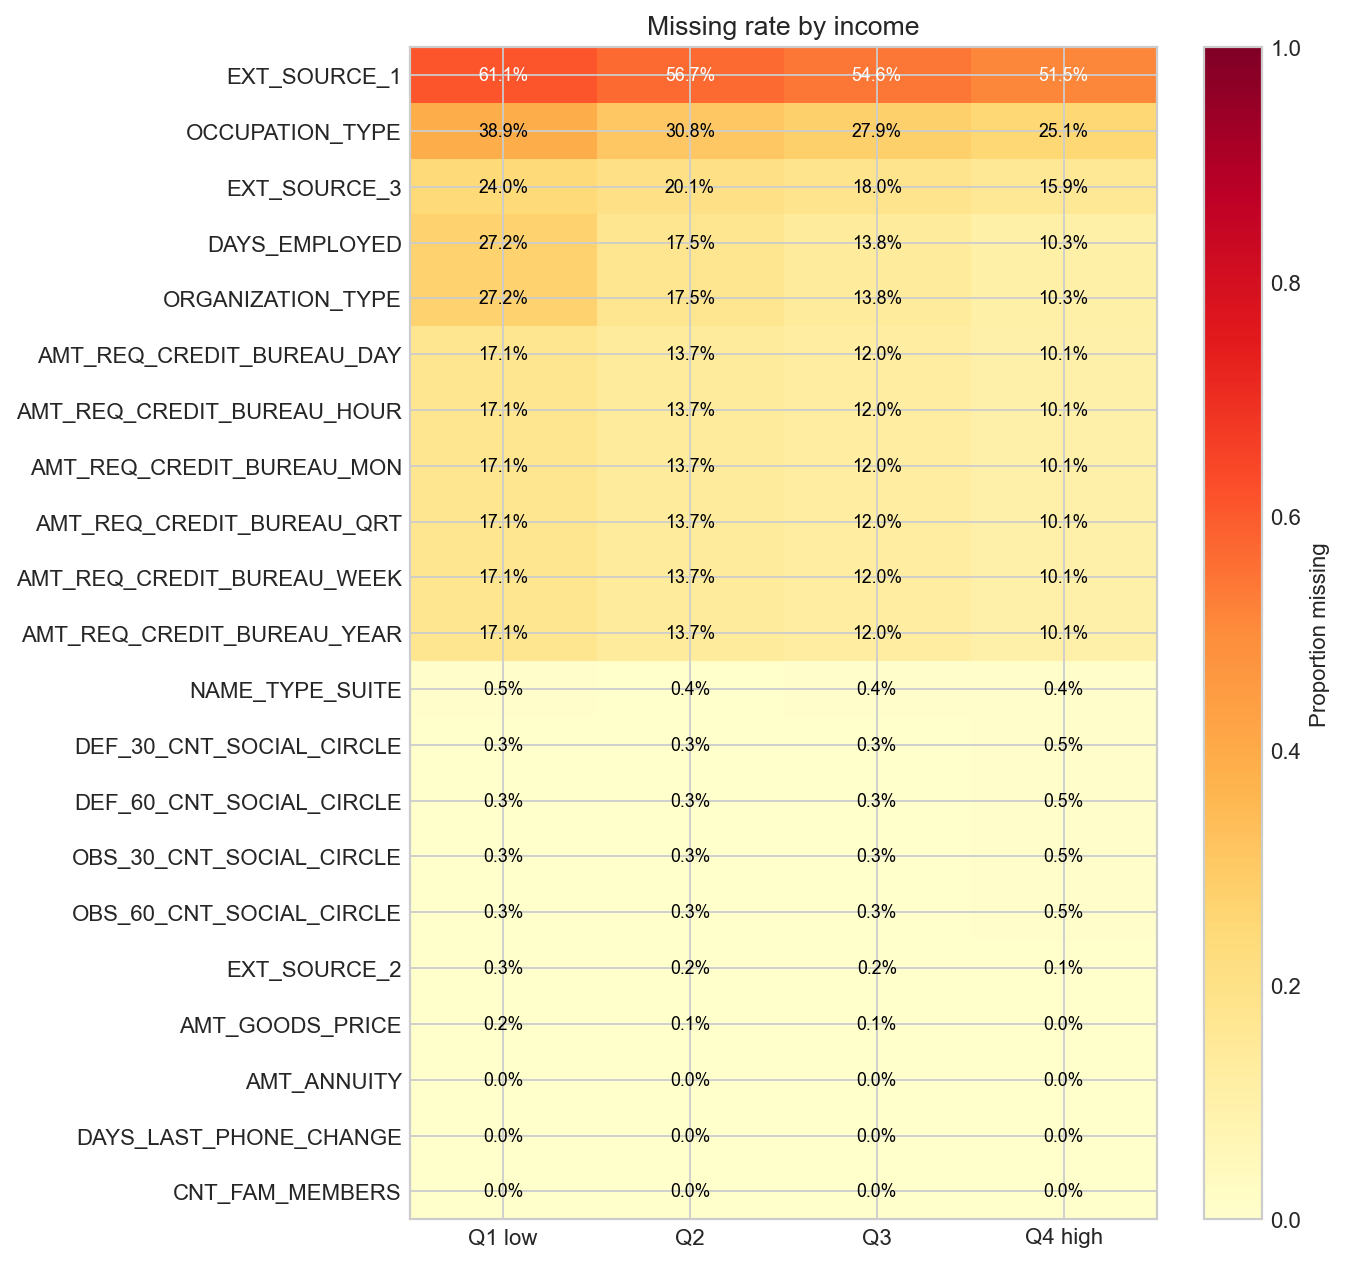

In [307]:
show_group_rates("Income", "income_band", INCOME_BANDS)

#### Default

Default is `TARGET = 1`. Non-default is `TARGET = 0`. The heatmap shows whether applicants who later default are missing a field more often, or less often, than applicants who do not. This is a description of the recorded outcome. It is a separate question from whether the model treats groups fairly.


,n_missing,overall,Non-default,Default
column,,,,
EXT_SOURCE_1,173375,0.563812,0.561073,0.595005
OCCUPATION_TYPE,96389,0.313455,0.318774,0.252890
EXT_SOURCE_3,60964,0.198254,0.195582,0.228681
DAYS_EMPLOYED,55374,0.180075,0.185312,0.120443
ORGANIZATION_TYPE,55374,0.180075,0.185312,0.120443
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.131690,0.172890
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.131690,0.172890
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.131690,0.172890
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.131690,0.172890


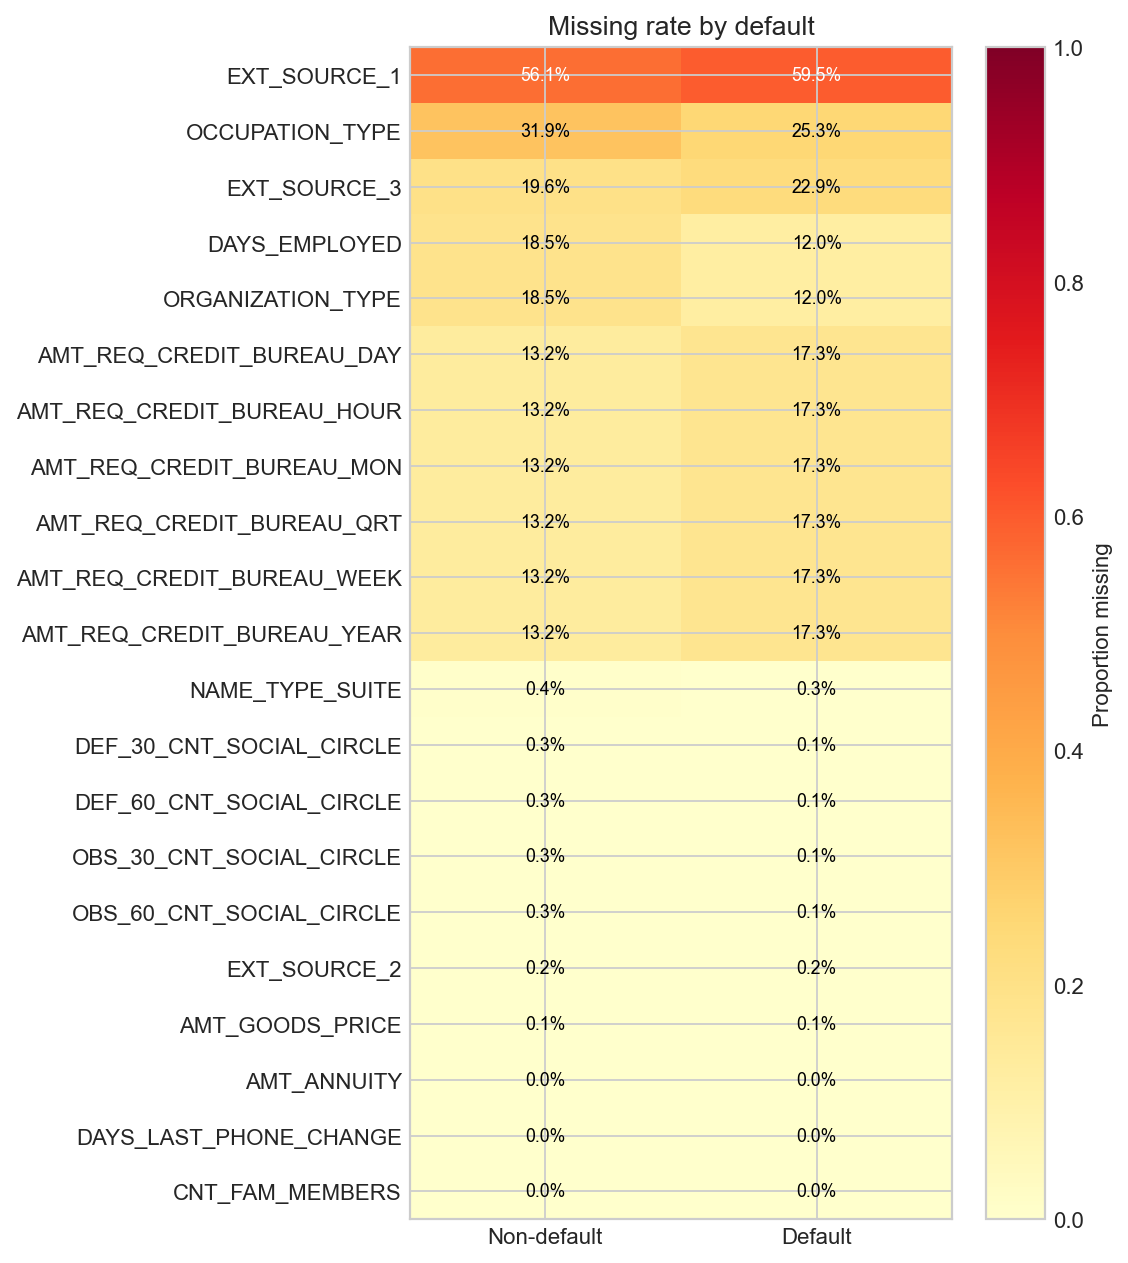

In [308]:
show_group_rates("Default", "default_status", DEFAULT_GROUPS)

### 2.2 Association With Gender, Age, Income, and Default

Section 2.1 shows the rates. This section asks whether the differences are large, and whether they remain when gender, age, income, and default are considered together.

For each retained field, missingness is crossed with one grouping at a time. The grouping is gender (2 levels), age band (6), income band (4), or default (2). The test is a chi-square test of independence on that contingency table:

$$
\chi^2 = \sum \frac{(O - E)^2}{E},
$$

where $O$ is the observed count and $E$ is the count expected if missingness and the grouping were independent. The size of the association is Cramér's V,

$$
V = \sqrt{\frac{\chi^2}{n \cdot \min(r - 1,\, c - 1)}},
$$

with $n$ the number of applications in the table, $r$ the number of rows, and $c$ the number of columns. $V$ is 0 when the missing rate does not vary by group. Larger values mean a stronger association. The table reports $V$ rather than $\chi^2$ because the sample is large enough for a very small rate gap to produce a very small p-value.

`rate_difference` is the gap in the missing rate, in percentage points:

- Gender: Male − Female. A negative value means men are missing the field less often than women.
- Age band: the highest missing-rate band minus the lowest. The contrast column names those two bands.
- Income: the highest missing-rate band minus the lowest, named the same way.
- Default: Default − Non-default.

The conclusion uses $\alpha = 0.05$. `h1_associated` means the p-value is below 0.05. `h0_not_associated` means it is not. `not_reliable` means the smallest expected count is below 5, so the chi-square approximation is a poor one. p-values are not adjusted for the number of fields or groupings.

The four figures repeat these gaps, one grouping per chart. The bar is the rate difference. The number at the bar is Cramér's V. Fields are ordered by the absolute gap in that grouping, largest at the top. Each chart has its own axis. The axis ends are rounded outward to a multiple of 5, then extended by 10% of that span on both sides, so the longest bar is not cut off by the frame.

Logistic regression then puts the four groupings in one model. A field is fit only when it has at least 30 missing values. The model and the odds-ratio figure are directly below.


In [309]:
from IPython.display import HTML
from scipy.stats import chi2_contingency

def cramers_v(chi2, table):
    n_observations = table.to_numpy().sum()
    n_rows, n_cols = table.shape
    return np.sqrt(chi2 / (n_observations * min(n_rows - 1, n_cols - 1)))

def group_rates(feature, group_name, levels):
    missing = analysis[feature].isna()
    return pd.Series({
        level: float(missing[analysis[group_name].eq(level)].mean())
        for level in levels
    })

chi_rows = []
comparisons = [
    ("Gender", "gender", GENDERS, "Male - Female", lambda rates: rates["Male"] - rates["Female"]),
    ("Age band", "age_band", AGE_BANDS, None, None),
    ("Income", "income_band", INCOME_BANDS, None, None),
    ("Default", "default_status", DEFAULT_GROUPS, "Default - Non-default", lambda rates: rates["Default"] - rates["Non-default"]),
]
for feature in retained_missing:
    n_missing = int(analysis[feature].isna().sum())
    if n_missing == 0:
        for grouping, *_ in comparisons:
            chi_rows.append({
                "feature": feature,
                "grouping": grouping,
                "n_missing": 0,
                "contrast": "",
                "rate_difference": np.nan,
                "chi2": np.nan,
                "dof": np.nan,
                "p_value": np.nan,
                "cramers_v": np.nan,
                "min_expected": np.nan,
            })
        continue
    for grouping, group_name, levels, contrast, difference in comparisons:
        rates = group_rates(feature, group_name, levels)
        if difference is None:
            higher = rates.idxmax()
            lower = rates.idxmin()
            contrast = f"{higher} - {lower}"
            rate_difference = float(rates[higher] - rates[lower])
        else:
            rate_difference = float(difference(rates))
        table = pd.crosstab(analysis[feature].isna(), analysis[group_name])
        chi2, p_value, dof, expected = chi2_contingency(table)
        chi_rows.append({
            "feature": feature,
            "grouping": grouping,
            "n_missing": n_missing,
            "contrast": contrast,
            "rate_difference": rate_difference,
            "chi2": float(chi2),
            "dof": int(dof),
            "p_value": float(p_value),
            "cramers_v": float(cramers_v(chi2, table)),
            "min_expected": float(expected.min()),
        })

chi_square = pd.DataFrame(chi_rows).set_index(["feature", "grouping"])
chi_square_report = chi_square.reset_index()
chi_square_report["conclusion"] = np.where(
    chi_square_report["min_expected"].lt(5) | chi_square_report["p_value"].isna(),
    "not_reliable",
    np.where(chi_square_report["p_value"].lt(0.05), "h1_associated", "h0_not_associated"),
)
chi_square_report["rate_difference"] = chi_square_report["rate_difference"].map(
    lambda value: "" if pd.isna(value) else f"{value * 100:.2f}%"
)
chi_square_report["cramers_v"] = chi_square_report["cramers_v"].map(
    lambda value: "" if pd.isna(value) else value
)
chi_square_report = chi_square_report[[
    "feature", "grouping", "n_missing", "conclusion", "cramers_v", "rate_difference"
]]
chi_square_report.to_csv(OUTPUT_DIR / "missingness_chi_square.csv", index=False)
display(HTML("<b>CHI-SQUARE TEST</b>" + chi_square_report.to_html(index=False)))

feature,grouping,n_missing,conclusion,cramers_v,rate_difference
EXT_SOURCE_1,Gender,173375,h1_associated,0.046106,4.82%
EXT_SOURCE_1,Age band,173375,h1_associated,0.269105,43.67%
EXT_SOURCE_1,Income,173375,h1_associated,0.074465,9.57%
EXT_SOURCE_1,Default,173375,h1_associated,0.018628,3.39%
OCCUPATION_TYPE,Gender,96389,h1_associated,0.143487,-14.04%
OCCUPATION_TYPE,Age band,96389,h1_associated,0.522294,75.90%
OCCUPATION_TYPE,Income,96389,h1_associated,0.119999,13.81%
OCCUPATION_TYPE,Default,96389,h1_associated,0.038677,-6.59%
EXT_SOURCE_3,Gender,60964,h1_associated,0.026183,2.20%
EXT_SOURCE_3,Age band,60964,h1_associated,0.083673,16.66%


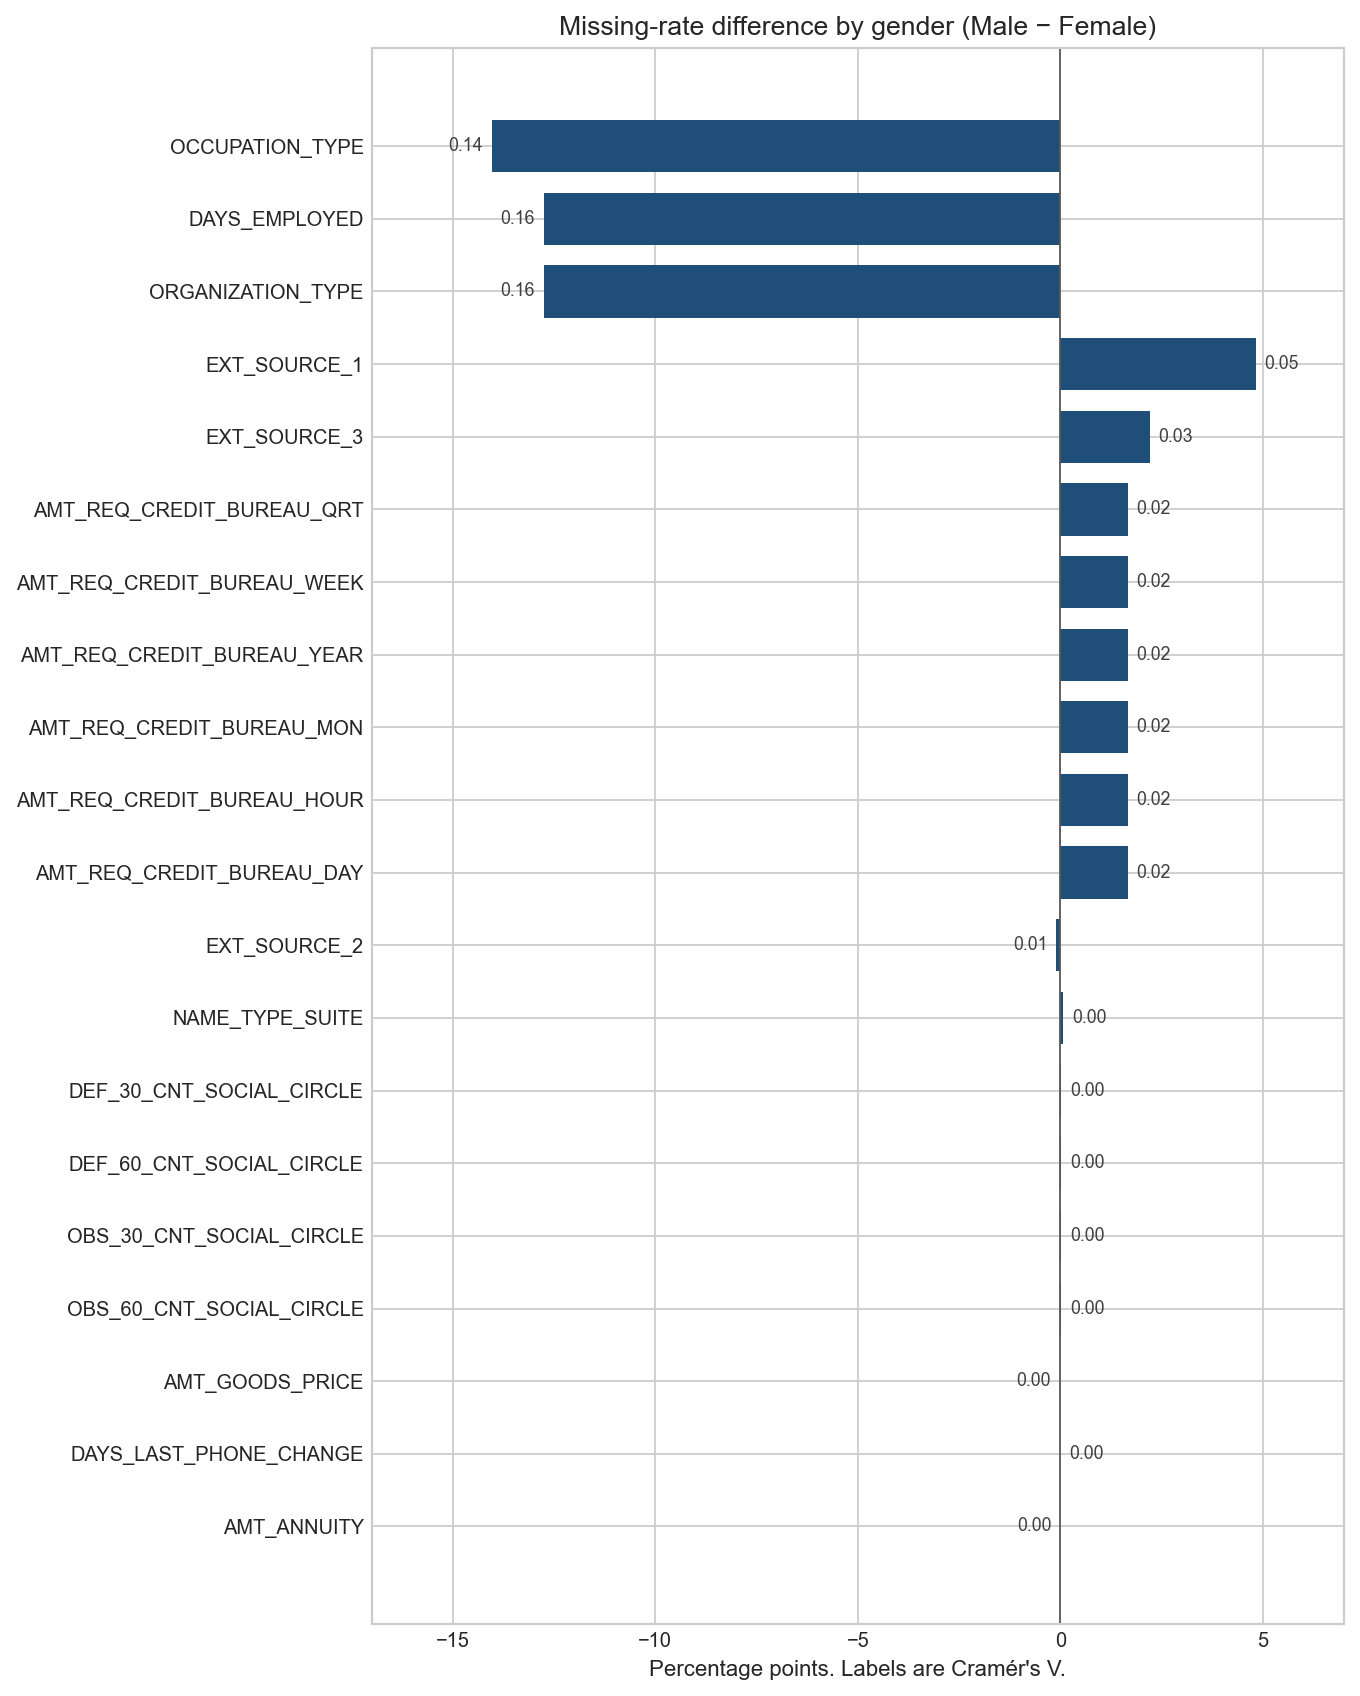

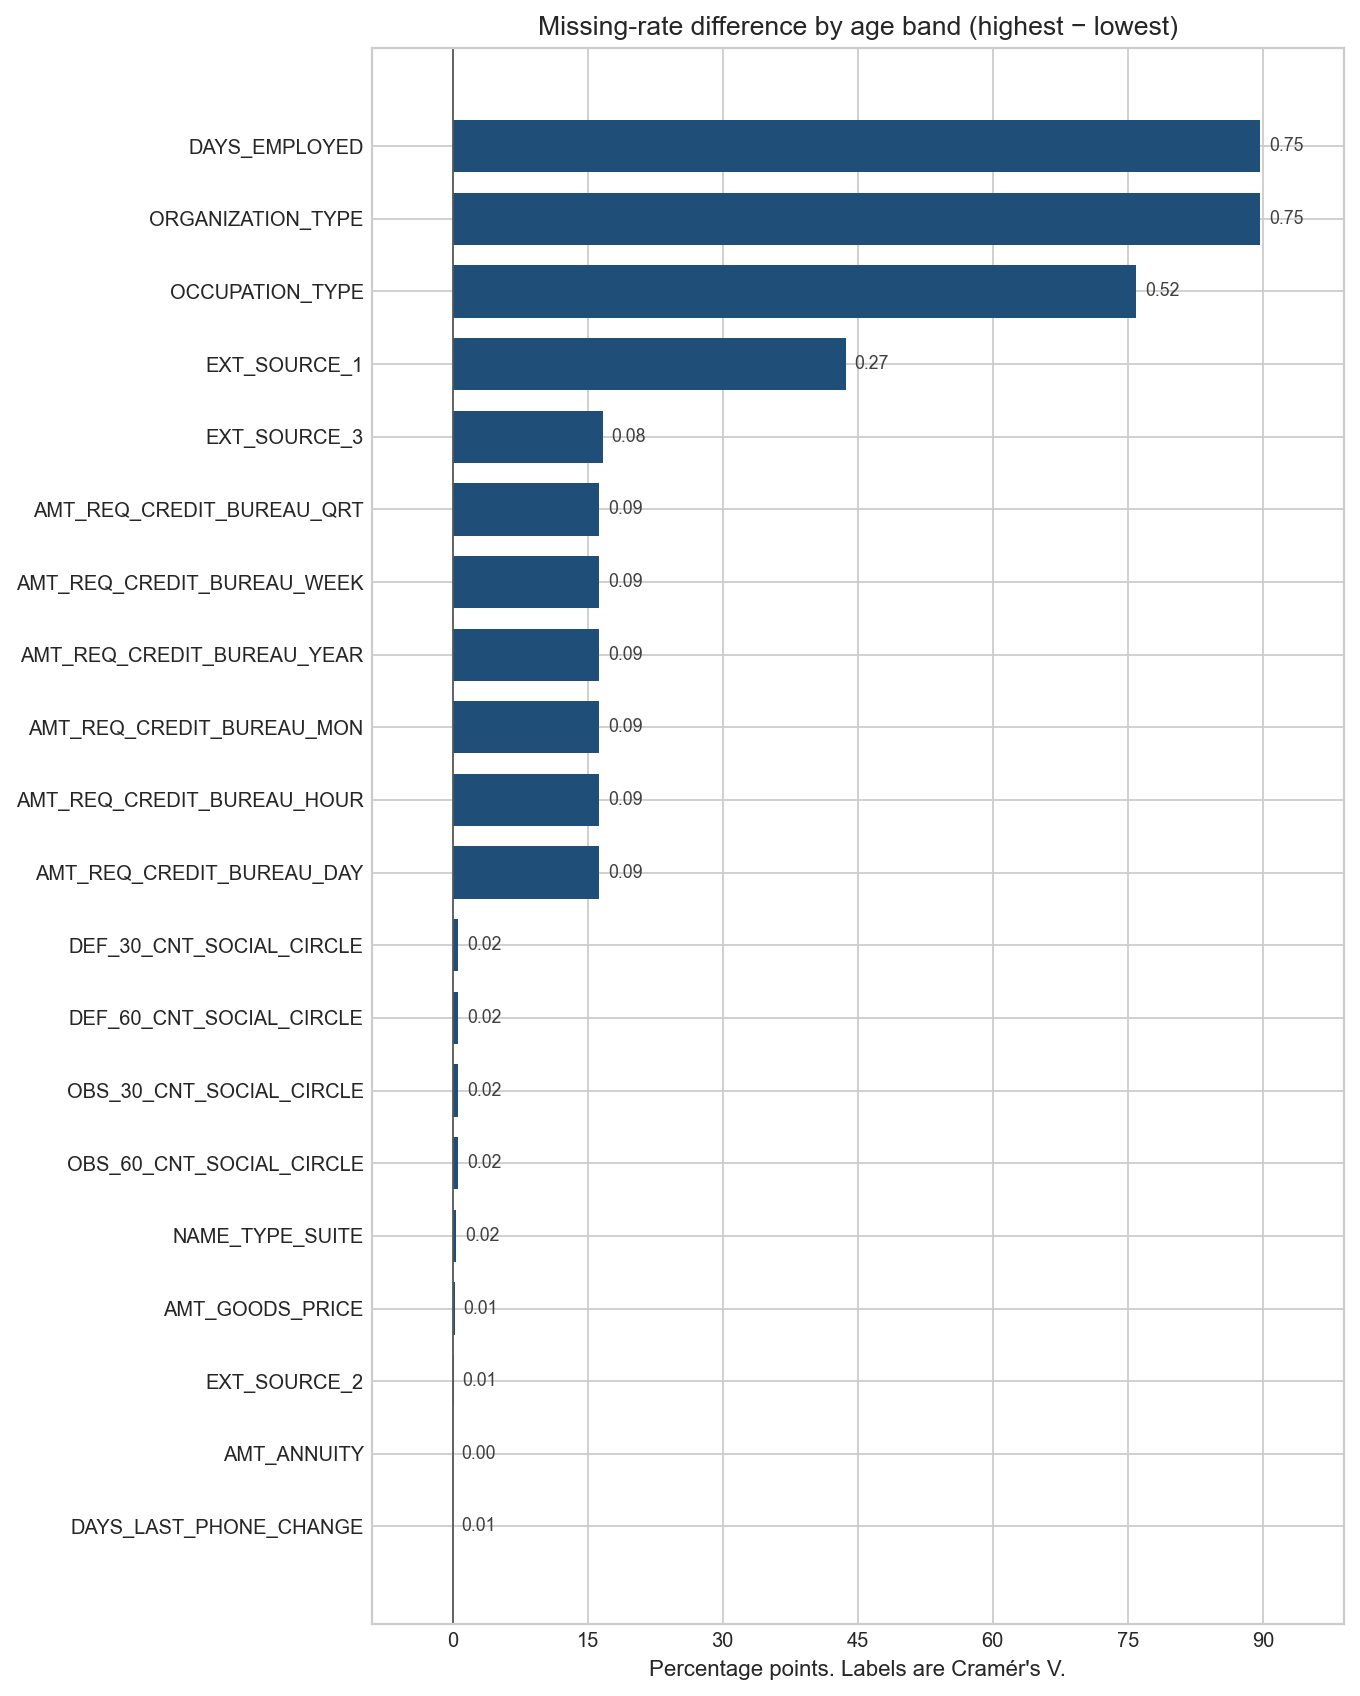

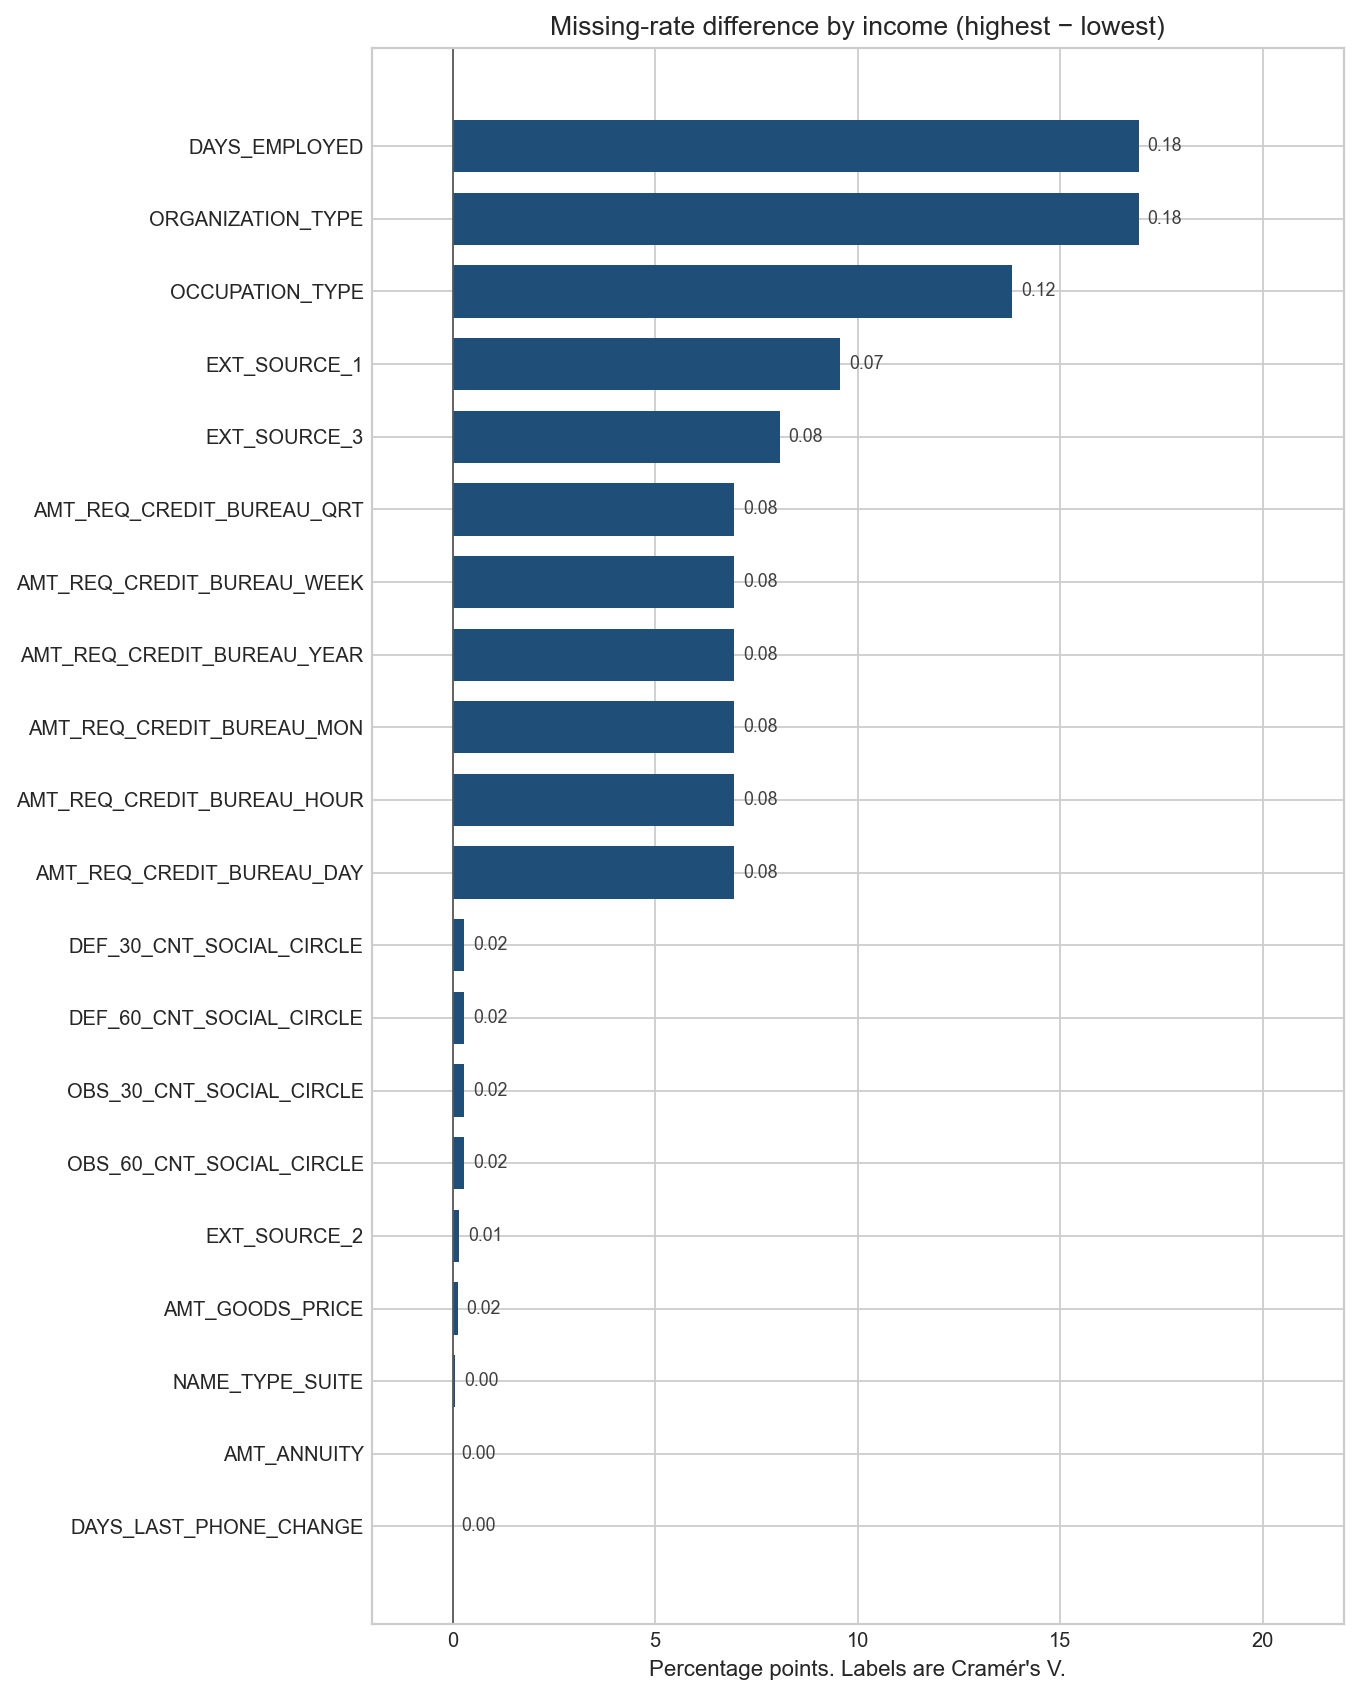

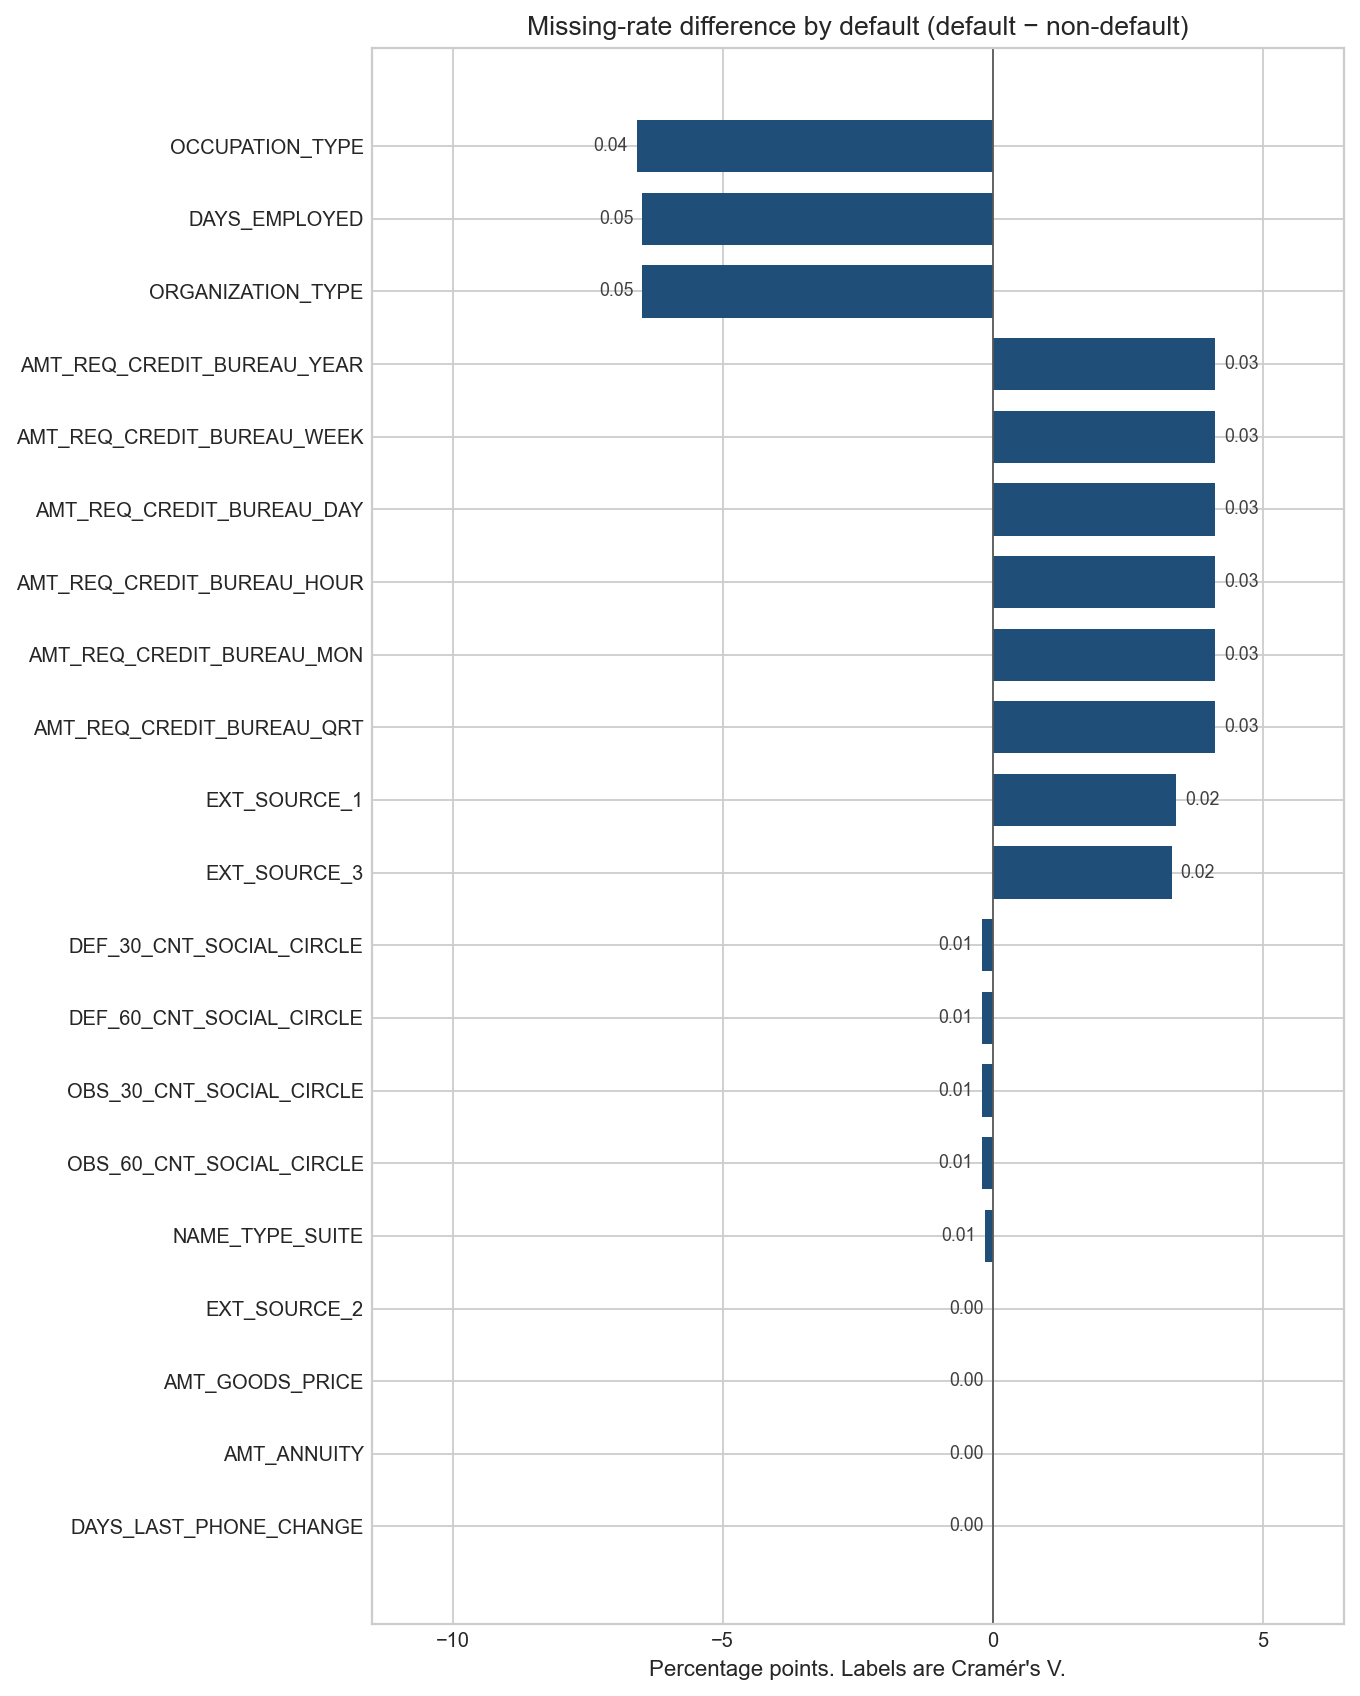

In [310]:
import numpy as np

figure_dir = OUTPUT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
effect = chi_square.reset_index().dropna(subset=["rate_difference", "cramers_v"])
groupings = ["Gender", "Age band", "Income", "Default"]
panel_titles = {
    "Gender": "Missing-rate difference by gender (Male − Female)",
    "Age band": "Missing-rate difference by age band (highest − lowest)",
    "Income": "Missing-rate difference by income (highest − lowest)",
    "Default": "Missing-rate difference by default (default − non-default)",
}
slugs = {
    "Gender": "gender",
    "Age band": "age_band",
    "Income": "income",
    "Default": "default",
}

def axis_limits(values):
    left = min(0, np.floor(np.nanmin(values) / 5) * 5)
    right = max(0, np.ceil(np.nanmax(values) / 5) * 5)
    if left == right:
        right = left + 5
    pad = 0.10 * (right - left)
    return float(left), float(right), float(left - pad), float(right + pad)

def axis_ticks(left, right):
    span = right - left
    step = 5 if span <= 30 else 10 if span <= 60 else 15
    return np.arange(left, right + step / 2, step)

for grouping in groupings:
    part = effect[effect["grouping"].eq(grouping)].copy()
    part["points"] = part["rate_difference"] * 100
    part = part.sort_values("points", key=lambda series: series.abs(), ascending=False)
    features = part["feature"].tolist()
    values = part["points"].to_numpy()
    positions = np.arange(len(features))
    tick_left, tick_right, left, right = axis_limits(values)
    figure, axis = plt.subplots(figsize=(8.6, 0.46 * len(features) + 1.5))
    axis.barh(positions, values, color="#1f4e79", height=0.72)
    axis.axvline(0, color="0.35", linewidth=0.8)
    room = max(1.2, 0.07 * (right - left))
    for position, value, association in zip(positions, values, part["cramers_v"]):
        if np.isnan(value):
            continue
        if value >= 0:
            outside = value <= right - room
            offset = (4, 0) if outside else (-4, 0)
            alignment = "left" if outside else "right"
        else:
            outside = value >= left + room
            offset = (-4, 0) if outside else (4, 0)
            alignment = "right" if outside else "left"
        axis.annotate(
            f"{association:.2f}",
            xy=(value, position),
            xytext=offset,
            textcoords="offset points",
            va="center",
            ha=alignment,
            fontsize=8,
            color="0.25",
        )
    axis.set_yticks(positions, features, fontsize=9)
    axis.tick_params(axis="x", labelsize=9)
    axis.invert_yaxis()
    axis.set_xlim(left, right)
    axis.set_xticks(axis_ticks(tick_left, tick_right))
    axis.set_xlabel("Percentage points. Labels are Cramér's V.", fontsize=10)
    axis.set_title(panel_titles[grouping], fontsize=12)
    figure.tight_layout()
    figure.savefig(
        figure_dir / f"missingness_rate_difference_{slugs[grouping]}.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()


For each retained field, $M = 1$ when the value is missing:

$$
\log\left(\frac{P(M=1)}{1-P(M=1)}\right)
= \beta_0
+ \beta_{\mathrm{male}}\mathrm{Male}
+ \beta_{\mathrm{age}}\mathrm{Age}
+ \beta_{Q2}I_{Q2}
+ \beta_{Q3}I_{Q3}
+ \beta_{Q4}I_{Q4}
+ \beta_{\mathrm{default}}\mathrm{Default}.
$$

Male is 1 for men and 0 for women. Age is in years. $I_{Q2}$, $I_{Q3}$, and $I_{Q4}$ are indicators for those income quartiles, with Q1 low as the reference. Default is 1 for a default and 0 otherwise. The table reports $e^{\beta}$, the multiplicative change in the odds of a missing value for a one-unit change in that term, holding the other terms fixed. An odds ratio of 1 means no change. The conclusion next to each term uses $\alpha = 0.05$, again without adjustment for the number of tests.

The figure plots these odds ratios for every field that was fit. Each panel is one term. The horizontal axis is logarithmic, and the vertical line is an odds ratio of 1. A point to the right of the line means higher odds of missing. A point to the left means lower odds. Fields with fewer than 30 missing values are left out, because the model is not fit for them.


In [311]:
import warnings

import statsmodels.api as sm

MIN_LOGIT_MISSING = 30

def association_label(p_value):
    if pd.isna(p_value):
        return ""
    if p_value < 0.05:
        return "h1_associated"
    return "h0_not_associated"

logit_rows = []
design = sm.add_constant(pd.DataFrame({
    "male": analysis["gender"].eq("Male").astype(float),
    "age_years": analysis["age_years"].astype(float),
    "income_q2": analysis["income_band"].eq("Q2").astype(float),
    "income_q3": analysis["income_band"].eq("Q3").astype(float),
    "income_q4": analysis["income_band"].eq("Q4 high").astype(float),
    "default": analysis["TARGET"].astype(float),
}), has_constant="add")
for feature in retained_missing:
    n_missing = int(analysis[feature].isna().sum())
    row = {
        "n_missing": n_missing,
        "odds_ratio_male": np.nan,
        "p_male": np.nan,
        "odds_ratio_age_per_year": np.nan,
        "p_age": np.nan,
        "odds_ratio_income_q2": np.nan,
        "p_income_q2": np.nan,
        "odds_ratio_income_q3": np.nan,
        "p_income_q3": np.nan,
        "odds_ratio_income_q4": np.nan,
        "p_income_q4": np.nan,
        "odds_ratio_default": np.nan,
        "p_default": np.nan,
    }
    if n_missing >= MIN_LOGIT_MISSING:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = sm.Logit(analysis[feature].isna().astype(int), design).fit(
                    disp=False, maxiter=200, method="lbfgs"
                )
            converged = bool(result.mle_retvals.get("converged", False))
            odds_ratios = np.exp(result.params)
            if converged and np.isfinite(odds_ratios.drop(labels="const")).all():
                row.update({
                    "odds_ratio_male": float(odds_ratios["male"]),
                    "p_male": float(result.pvalues["male"]),
                    "odds_ratio_age_per_year": float(odds_ratios["age_years"]),
                    "p_age": float(result.pvalues["age_years"]),
                    "odds_ratio_income_q2": float(odds_ratios["income_q2"]),
                    "p_income_q2": float(result.pvalues["income_q2"]),
                    "odds_ratio_income_q3": float(odds_ratios["income_q3"]),
                    "p_income_q3": float(result.pvalues["income_q3"]),
                    "odds_ratio_income_q4": float(odds_ratios["income_q4"]),
                    "p_income_q4": float(result.pvalues["income_q4"]),
                    "odds_ratio_default": float(odds_ratios["default"]),
                    "p_default": float(result.pvalues["default"]),
                })
        except Exception:
            pass
    logit_rows.append(row)

logit_results = pd.DataFrame(logit_rows, index=retained_missing)
logit_results.index.name = "feature"
for p_column, conclusion_column in {
    "p_male": "male",
    "p_age": "age",
    "p_income_q2": "income_q2",
    "p_income_q3": "income_q3",
    "p_income_q4": "income_q4",
    "p_default": "default",
}.items():
    logit_results[conclusion_column] = logit_results[p_column].map(association_label)
logit_results = logit_results[[
    "n_missing",
    "odds_ratio_male", "male",
    "odds_ratio_age_per_year", "age",
    "odds_ratio_income_q2", "income_q2",
    "odds_ratio_income_q3", "income_q3",
    "odds_ratio_income_q4", "income_q4",
    "odds_ratio_default", "default",
]]
logit_results.to_csv(OUTPUT_DIR / "missingness_logit.csv")
display(logit_results)

,n_missing,odds_ratio_male,male,odds_ratio_age_per_year,age,odds_ratio_income_q2,income_q2,odds_ratio_income_q3,income_q3,odds_ratio_income_q4,income_q4,odds_ratio_default,default
feature,,,,,,,,,,,,,
EXT_SOURCE_1,173375,1.601551,h1_associated,1.052237,h1_associated,0.852398,h1_associated,0.769039,h1_associated,0.646655,h1_associated,1.312359,h1_associated
OCCUPATION_TYPE,96389,0.663323,h1_associated,1.090583,h1_associated,0.795585,h1_associated,0.729987,h1_associated,0.655327,h1_associated,0.964970,h1_associated
EXT_SOURCE_3,60964,1.222737,h1_associated,0.990734,h1_associated,0.767688,h1_associated,0.657867,h1_associated,0.557727,h1_associated,1.145111,h1_associated
DAYS_EMPLOYED,55374,0.479382,h1_associated,1.339920,h1_associated,0.595888,h1_associated,0.477859,h1_associated,0.371671,h1_associated,1.067856,h1_associated
ORGANIZATION_TYPE,55374,0.479382,h1_associated,1.339920,h1_associated,0.595888,h1_associated,0.477859,h1_associated,0.371671,h1_associated,1.067856,h1_associated
AMT_REQ_CREDIT_BUREAU_DAY,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated
AMT_REQ_CREDIT_BUREAU_HOUR,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated
AMT_REQ_CREDIT_BUREAU_MON,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated
AMT_REQ_CREDIT_BUREAU_QRT,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated


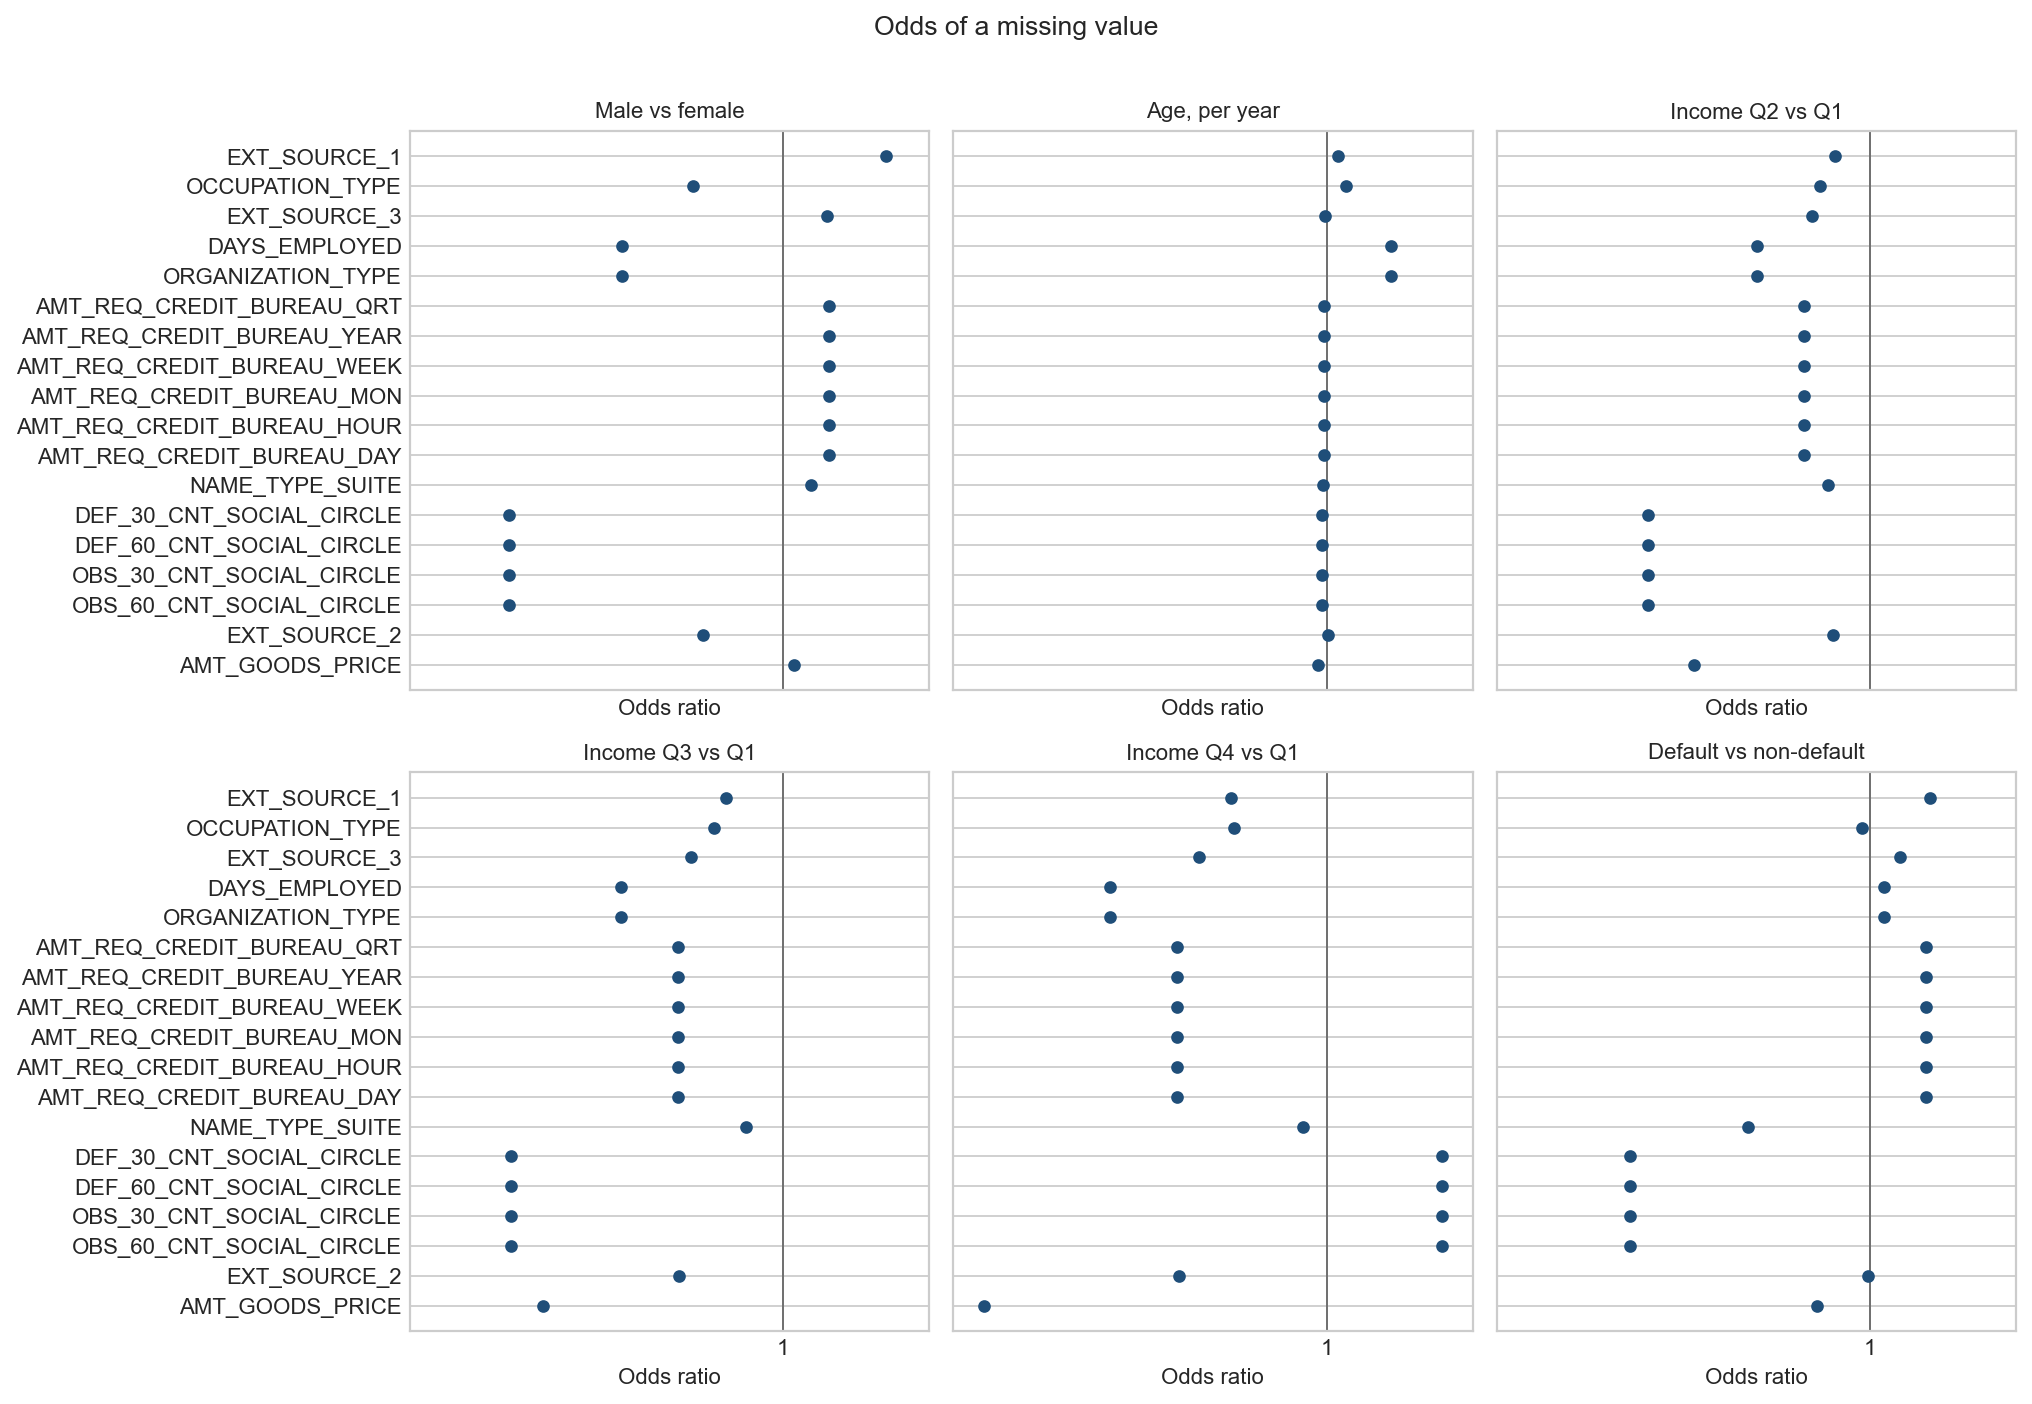

In [312]:
import numpy as np

figure_dir = OUTPUT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
terms = [
    ("odds_ratio_male", "Male vs female"),
    ("odds_ratio_age_per_year", "Age, per year"),
    ("odds_ratio_income_q2", "Income Q2 vs Q1"),
    ("odds_ratio_income_q3", "Income Q3 vs Q1"),
    ("odds_ratio_income_q4", "Income Q4 vs Q1"),
    ("odds_ratio_default", "Default vs non-default"),
]
columns = [column for column, _title in terms]
fitted = logit_results.dropna(subset=columns, how="all").sort_values("n_missing", ascending=False)
features = fitted.index.astype(str).tolist()
positions = np.arange(len(features))
odds = fitted[columns].to_numpy()
finite = odds[np.isfinite(odds)]
figure, axes = plt.subplots(2, 3, figsize=(12.8, 0.38 * len(features) + 1.8), sharex=True, sharey=True)
for axis, (column, title) in zip(axes.ravel(), terms):
    axis.scatter(fitted[column], positions, s=22, color="#1f4e79", zorder=3)
    axis.axvline(1, color="0.4", linewidth=0.8)
    axis.set_xscale("log")
    axis.xaxis.set_major_formatter(plt.FuncFormatter(
        lambda value, _position: "1" if np.isclose(value, 1) else f"{value:g}"
    ))
    axis.set_title(title, fontsize=10)
    axis.set_xlabel("Odds ratio")
low = finite.min() / 1.15
high = finite.max() * 1.15
for axis in axes.ravel():
    axis.set_xlim(low, high)
axes[0, 0].set_yticks(positions, features)
axes[0, 0].invert_yaxis()
figure.suptitle("Odds of a missing value", y=1.01)
figure.tight_layout()
figure.savefig(figure_dir / "missingness_odds_ratios.png", dpi=160, bbox_inches="tight")
plt.show()


### 2.3 MCAR Test

Sections 2.1 and 2.2 show that missingness varies by group. This section asks a narrower question: for a numeric subset, is the pattern of missing values consistent with missing completely at random?

Little's MCAR test compares the observed means in each missingness pattern with the means implied by a single set of population means and covariances. Let pattern $j$ contain $n_j$ rows, and let $\mathrm{obs}$ denote the variables observed in that pattern. The statistic is

$$
d^2 = \sum_j n_j
\left(\bar y_{j,\mathrm{obs}} - \hat\mu_{j,\mathrm{obs}}\right)^\top
\hat\Sigma_{j,\mathrm{obs}}^{-1}
\left(\bar y_{j,\mathrm{obs}} - \hat\mu_{j,\mathrm{obs}}\right).
$$

Under the null, $d^2$ is compared with a chi-square distribution. The degrees of freedom equal the number of observed pattern-variable pairs minus the number of variables. The test assumes multivariate normality. It is a test for quantitative fields, so it is not run on all 21 retained fields.

$$
H_0:\text{the included fields are MCAR}.
$$

$$
H_1:\text{the included fields are not MCAR}.
$$

A p-value below 0.05 rejects MCAR. A larger p-value fails to reject it. Failing to reject MCAR does not prove that the data are MCAR. Rejecting MCAR also does not say whether the mechanism is missing at random or missing not at random.

The first table records which retained fields enter the test.

| Decision | Fields |
| --- | --- |
| Included | `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`, `AMT_GOODS_PRICE`, `DAYS_EMPLOYED`, `CNT_FAM_MEMBERS`, plus one representative of the bureau fields and one of the social-circle fields |
| Excluded, categorical | `OCCUPATION_TYPE`, `NAME_TYPE_SUITE`, `ORGANIZATION_TYPE` |
| Excluded, same missing rows as the representative | the other five bureau fields, and the other three social-circle fields |
| Excluded, too few missing values | `AMT_ANNUITY`, `DAYS_LAST_PHONE_CHANGE` |

`DAYS_EMPLOYED = 365243` is already treated as missing. `AMT_REQ_CREDIT_BUREAU_YEAR` stands in for the six bureau fields, which are missing on the same rows. `OBS_30_CNT_SOCIAL_CIRCLE` stands in for the four social-circle fields, which are missing on the same rows. `CNT_FAM_MEMBERS` is included as a numeric field that is fully observed, so it contributes to the estimated mean and covariance.

The second table is the test: the statistic $d^2$, its degrees of freedom, the p-value, and the conclusion at $\alpha = 0.05$.


In [313]:
import numpy as np
from IPython.display import HTML
from scipy.stats import chi2

CATEGORICAL_FIELDS = ["OCCUPATION_TYPE", "NAME_TYPE_SUITE", "ORGANIZATION_TYPE"]
BUREAU_FIELDS = [column for column in retained_missing if column.startswith("AMT_REQ_CREDIT_BUREAU_")]
SOCIAL_FIELDS = [column for column in retained_missing if column.endswith("_SOCIAL_CIRCLE")]
BUREAU_REPRESENTATIVE = "AMT_REQ_CREDIT_BUREAU_YEAR"
SOCIAL_REPRESENTATIVE = "OBS_30_CNT_SOCIAL_CIRCLE"
SPARSE_FIELDS = ["AMT_ANNUITY", "DAYS_LAST_PHONE_CHANGE"]
MCAR_FIELDS = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_GOODS_PRICE",
    "DAYS_EMPLOYED",
    BUREAU_REPRESENTATIVE,
    SOCIAL_REPRESENTATIVE,
    "CNT_FAM_MEMBERS",
]

def little_mcar_test(frame, max_iter=200, tol=1e-6):
    values = frame.to_numpy(dtype=float)
    n_rows, n_variables = values.shape
    observed = np.isfinite(values)
    pattern_keys = np.ascontiguousarray(observed).view(
        np.dtype((np.void, observed.shape[1]))
    ).ravel()
    order = np.argsort(pattern_keys, kind="mergesort")
    sorted_keys = pattern_keys[order]
    breaks = np.flatnonzero(sorted_keys[1:] != sorted_keys[:-1]) + 1
    groups = []
    start = 0
    for end in np.r_[breaks, n_rows]:
        row_index = order[start:end]
        groups.append((row_index, observed[row_index[0]]))
        start = end

    mean = np.nanmean(values, axis=0)
    filled = np.where(observed, values, mean)
    covariance = np.cov(filled, rowvar=False, ddof=0)
    covariance.flat[:: n_variables + 1] += 1e-8

    def expected_statistics(mean, covariance):
        total = np.zeros(n_variables)
        second = np.zeros((n_variables, n_variables))
        for row_index, is_observed in groups:
            block = values[row_index]
            n_pattern = len(row_index)
            if is_observed.all():
                total += block.sum(axis=0)
                second += block.T @ block
                continue
            observed_index = np.flatnonzero(is_observed)
            missing_index = np.flatnonzero(~is_observed)
            observed_covariance = covariance[np.ix_(observed_index, observed_index)]
            observed_covariance = observed_covariance + 1e-8 * np.eye(len(observed_index))
            cross_covariance = covariance[np.ix_(missing_index, observed_index)]
            missing_covariance = covariance[np.ix_(missing_index, missing_index)]
            observed_values = block[:, observed_index]
            coefficient = np.linalg.solve(observed_covariance, cross_covariance.T).T
            conditional_mean = mean[missing_index] + (observed_values - mean[observed_index]) @ coefficient.T
            conditional_covariance = missing_covariance - coefficient @ cross_covariance.T
            sum_values = np.zeros(n_variables)
            sum_values[observed_index] = observed_values.sum(axis=0)
            sum_values[missing_index] = conditional_mean.sum(axis=0)
            total += sum_values
            second[np.ix_(observed_index, observed_index)] += observed_values.T @ observed_values
            second[np.ix_(missing_index, missing_index)] += (
                n_pattern * conditional_covariance + conditional_mean.T @ conditional_mean
            )
            cross = observed_values.T @ conditional_mean
            second[np.ix_(observed_index, missing_index)] += cross
            second[np.ix_(missing_index, observed_index)] += cross.T
        return total, second

    for _ in range(max_iter):
        total, second = expected_statistics(mean, covariance)
        next_mean = total / n_rows
        next_covariance = second / n_rows - np.outer(next_mean, next_mean)
        next_covariance = 0.5 * (next_covariance + next_covariance.T)
        next_covariance.flat[:: n_variables + 1] += 1e-8
        change = max(
            np.max(np.abs(next_mean - mean)),
            np.max(np.abs(next_covariance - covariance)),
        )
        mean, covariance = next_mean, next_covariance
        if change < tol:
            break
    else:
        raise RuntimeError("Little's MCAR expectation-maximisation did not converge.")

    statistic = 0.0
    degrees_of_freedom = -n_variables
    for row_index, is_observed in groups:
        observed_index = np.flatnonzero(is_observed)
        pattern_mean = values[row_index][:, observed_index].mean(axis=0)
        difference = pattern_mean - mean[observed_index]
        pattern_covariance = covariance[np.ix_(observed_index, observed_index)]
        pattern_covariance = pattern_covariance + 1e-10 * np.eye(len(observed_index))
        statistic += len(row_index) * float(difference @ np.linalg.solve(pattern_covariance, difference))
        degrees_of_freedom += len(observed_index)
    if degrees_of_freedom <= 0:
        raise ValueError(f"Little's MCAR test has {degrees_of_freedom} degrees of freedom.")
    p_value = float(chi2.sf(statistic, degrees_of_freedom))
    return float(statistic), int(degrees_of_freedom), p_value

selection_rows = []
for column in retained_missing:
    if column in CATEGORICAL_FIELDS or column in SPARSE_FIELDS:
        decision = "Excluded"
    elif column in BUREAU_FIELDS and column != BUREAU_REPRESENTATIVE:
        decision = "Excluded"
    elif column in SOCIAL_FIELDS and column != SOCIAL_REPRESENTATIVE:
        decision = "Excluded"
    else:
        decision = "Included"
    selection_rows.append({"column": column, "decision": decision})

mcar_selection = pd.DataFrame(selection_rows)
mcar_selection.to_csv(OUTPUT_DIR / "mcar_field_selection.csv", index=False)
display(mcar_selection)

statistic, degrees_of_freedom, p_value = little_mcar_test(analysis[MCAR_FIELDS])
mcar_result = pd.DataFrame({
    "statistic": [statistic],
    "df": [degrees_of_freedom],
    "p_value": ["<1e-300" if p_value == 0 else f"{p_value:.3e}"],
    "conclusion": ["h1_not_mcar" if p_value < 0.05 else "h0_mcar"],
})
mcar_result.to_csv(OUTPUT_DIR / "littles_mcar_test.csv", index=False)
display(HTML("<b>LITTLE MCAR TEST</b>" + mcar_result.to_html(index=False)))


,column,decision
0,EXT_SOURCE_1,Included
1,OCCUPATION_TYPE,Excluded
2,EXT_SOURCE_3,Included
3,DAYS_EMPLOYED,Included
4,ORGANIZATION_TYPE,Excluded
5,AMT_REQ_CREDIT_BUREAU_DAY,Excluded
6,AMT_REQ_CREDIT_BUREAU_HOUR,Excluded
7,AMT_REQ_CREDIT_BUREAU_MON,Excluded
8,AMT_REQ_CREDIT_BUREAU_QRT,Excluded
9,AMT_REQ_CREDIT_BUREAU_WEEK,Excluded


statistic,df,p_value,conclusion
"39,246.508489",255,<1e-300,h1_not_mcar


## 3. Outlier and Winsorization Audit

This section describes where extreme values sit: whether they concentrate in particular demographic groups, and whether the caps already used in training fall on particular groups or on applications with a different default rate.

The description follows the preprocessing that was used to train the XGBoost and MLP models. The models are not retrained. The split is not changed. The caps are not refit.

The rules come from the shared preprocessing cell in `xgboost_mlp.ipynb`. The modeling sample drops `CODE_GENDER = XNA` and `NAME_FAMILY_STATUS = Unknown`, then uses the same 70/15/15 split stratified on `TARGET` with seed 42. That split has 215,253 training applications, 46,126 validation applications, and 46,126 test applications.

A value is capped only when it is observed and strictly greater than its cap. Missing values stay out of the denominator, so a missing value is not counted as an outlier.

Four monetary fields are capped at the 99th percentile of the training observations. That cap is then applied to training, validation, and test:

$$
c = Q_{0.99}(x_{\text{train}}).
$$

The monetary fields are `AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, and `AMT_GOODS_PRICE`. Five fields use a fixed cap: `CNT_CHILDREN` at 10, `CNT_FAM_MEMBERS` at 10, `OBS_30_CNT_SOCIAL_CIRCLE` at 30, `OBS_60_CNT_SOCIAL_CIRCLE` at 30, and `AMT_REQ_CREDIT_BUREAU_QRT` at 20.


### 3.1 Outlier Prevalence

This subsection counts how many observed values exceed each cap, and how far the raw upper tail extends beyond it.

For each field, among observed values,

$$
\text{percent exceeding} = 100 \times \frac{\text{number of values strictly above the cap}}{\text{number of observed values}}.
$$

The overall table reports, for each of the nine capped fields, how many values are observed, how many are missing, the minimum, the median, the maximum, the cap, the number above the cap, and the percent above the cap. A monetary cap near the 99th percentile should flag about 1% of observed training values. The fixed caps flag far fewer rows, because almost every recorded value already sits at or below the constant.

The second table splits the four monetary fields by training, validation, and test. The same training cap is used in every split. The counts of values above the cap, added across the three splits, match the overall count for that field.

The figure places the median, the cap, and the maximum on a logarithmic axis. The navy point is the median, the red diamond is the cap, and the slate point is the maximum. A long line to the right of the diamond is a tail that the cap pulls in. A median of zero is omitted, which is why children has no median marker. The line for that field starts at the cap.


In [314]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML
from sklearn.model_selection import train_test_split

SEED = 42
AUDIT_DIR = Path("output") / "audit" / "outlier_winsorization"
FIGURE_DIR = AUDIT_DIR / "figures"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MONETARY_FEATURES = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
FIXED_CAPS = {
    "CNT_CHILDREN": 10,
    "CNT_FAM_MEMBERS": 10,
    "OBS_30_CNT_SOCIAL_CIRCLE": 30,
    "OBS_60_CNT_SOCIAL_CIRCLE": 30,
    "AMT_REQ_CREDIT_BUREAU_QRT": 20,
}
AGE_LABELS = ["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]

audit = (
    df.loc[~df["CODE_GENDER"].eq("XNA") & ~df["NAME_FAMILY_STATUS"].eq("Unknown")]
    .reset_index(drop=True)
)
n_before_split = len(audit)
y_audit = audit["TARGET"]
row_index = audit.index.to_numpy()
idx_train, idx_temp, y_train, y_temp = train_test_split(
    row_index, y_audit, test_size=0.30, stratify=y_audit, random_state=SEED
)
idx_val, idx_test, _, _ = train_test_split(
    idx_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
assert n_before_split == len(idx_train) + len(idx_val) + len(idx_test)
assert set(idx_train).isdisjoint(idx_val) and set(idx_val).isdisjoint(idx_test)

winsor_caps = {
    column: float(audit.loc[idx_train, column].quantile(0.99))
    for column in MONETARY_FEATURES
}
feature_caps = {**winsor_caps, **FIXED_CAPS}
audit["gender"] = audit["CODE_GENDER"].map({"F": "Female", "M": "Male"})
audit["age_band"] = pd.cut(
    -audit["DAYS_BIRTH"] / 365.25,
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=AGE_LABELS,
    right=False,
).astype("string")
assert audit["gender"].notna().all() and audit["age_band"].notna().all()

def capping_counts(series, cap):
    observed = series.dropna()
    n_nonmissing = int(len(observed))
    n_exceeding = int((observed > cap).sum())
    capped = observed.clip(upper=cap)
    unchanged = observed <= cap
    if n_nonmissing:
        assert (capped <= observed + 1e-8).all()
        assert np.allclose(capped[unchanged], observed[unchanged])
        assert capped.max() <= cap + 1e-8
    return {
        "n_nonmissing": n_nonmissing,
        "n_missing": int(series.isna().sum()),
        "minimum": float(observed.min()) if n_nonmissing else np.nan,
        "median": float(observed.median()) if n_nonmissing else np.nan,
        "maximum": float(observed.max()) if n_nonmissing else np.nan,
        "cap": float(cap),
        "n_exceeding": n_exceeding,
        "pct_exceeding": 100 * n_exceeding / n_nonmissing if n_nonmissing else np.nan,
    }

prevalence_rows = []
for feature, cap in feature_caps.items():
    row = capping_counts(audit[feature], cap)
    row["feature"] = feature
    row["capping_method"] = "99th percentile" if feature in MONETARY_FEATURES else "Fixed threshold"
    prevalence_rows.append(row)
prevalence = (
    pd.DataFrame(prevalence_rows)
    .sort_values(["pct_exceeding", "feature"], ascending=[False, True])
    .reset_index(drop=True)
)
prevalence = prevalence[[
    "feature", "capping_method", "n_nonmissing", "n_missing", "minimum", "median",
    "maximum", "cap", "n_exceeding", "pct_exceeding",
]]
assert len(audit) == n_before_split
for feature, cap in winsor_caps.items():
    assert np.isclose(cap, audit.loc[idx_train, feature].quantile(0.99))
prevalence.to_csv(AUDIT_DIR / "outlier_prevalence.csv", index=False)

split_rows = []
for split_name, split_index in [("Training", idx_train), ("Validation", idx_val), ("Test", idx_test)]:
    for feature in MONETARY_FEATURES:
        counts = capping_counts(audit.loc[split_index, feature], feature_caps[feature])
        split_rows.append({
            "feature": feature,
            "split": split_name,
            "n_nonmissing": counts["n_nonmissing"],
            "n_exceeding": counts["n_exceeding"],
            "pct_exceeding": counts["pct_exceeding"],
        })
split_prevalence = pd.DataFrame(split_rows)
split_check = split_prevalence.groupby("feature")["n_exceeding"].sum()
for feature in MONETARY_FEATURES:
    assert int(split_check[feature]) == int(prevalence.loc[prevalence["feature"].eq(feature), "n_exceeding"].iloc[0])
split_prevalence.to_csv(AUDIT_DIR / "monetary_capping_by_split.csv", index=False)

def show_table(frame, title, percent_columns, merge_columns=None):
    shown = frame.copy()
    for column in percent_columns:
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:.2f}%")
    for column in shown.columns:
        if column in percent_columns or shown[column].dtype == object:
            continue
        if pd.api.types.is_integer_dtype(shown[column]):
            continue
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:,.2f}")
    if not merge_columns:
        display(HTML(f"<b>{title}</b>" + shown.to_html(index=False)))
        return
    columns = list(shown.columns)
    features = shown["feature"].tolist()
    spans = []
    start = 0
    while start < len(features):
        end = start + 1
        while end < len(features) and features[end] == features[start]:
            end += 1
        spans.append(end - start)
        start = end
    html = [f"<b>{title}</b><table border='1' class='dataframe'><thead><tr>"]
    html.extend(f"<th>{column}</th>" for column in columns)
    html.append("</tr></thead><tbody>")
    row_index = 0
    for span in spans:
        for offset in range(span):
            html.append("<tr>")
            for column in columns:
                if column in merge_columns:
                    if offset == 0:
                        html.append(
                            f"<td rowspan='{span}' style='vertical-align: middle'>{shown.iloc[row_index][column]}</td>"
                        )
                else:
                    html.append(f"<td>{shown.iloc[row_index][column]}</td>")
            html.append("</tr>")
            row_index += 1
    html.append("</tbody></table>")
    display(HTML("".join(html)))

show_table(
    prevalence,
    "OUTLIER PREVALENCE (OVERALL)",
    ["pct_exceeding"],
)
show_table(
    split_prevalence,
    "MONETARY CAPPING BY SPLIT",
    ["pct_exceeding"],
)

feature,capping_method,n_nonmissing,n_missing,minimum,median,maximum,cap,n_exceeding,pct_exceeding
AMT_ANNUITY,99th percentile,307493,12,"1,615.50","24,903.00","258,025.50","69,912.00",3085,1.00%
AMT_CREDIT,99th percentile,307505,0,"45,000.00","513,531.00","4,050,000.00","1,867,074.12",3044,0.99%
AMT_INCOME_TOTAL,99th percentile,307505,0,"25,650.00","147,150.00","117,000,000.00","495,000.00",2707,0.88%
AMT_GOODS_PRICE,99th percentile,307229,276,"40,500.00","450,000.00","4,050,000.00","1,800,000.00",1431,0.47%
CNT_FAM_MEMBERS,Fixed threshold,307505,0,1.00,2.00,20.00,10.00,11,0.00%
CNT_CHILDREN,Fixed threshold,307505,0,0.00,0.00,19.00,10.00,8,0.00%
OBS_30_CNT_SOCIAL_CIRCLE,Fixed threshold,306484,1021,0.00,0.00,348.00,30.00,2,0.00%
OBS_60_CNT_SOCIAL_CIRCLE,Fixed threshold,306484,1021,0.00,0.00,344.00,30.00,2,0.00%
AMT_REQ_CREDIT_BUREAU_QRT,Fixed threshold,265987,41518,0.00,0.00,261.00,20.00,1,0.00%


feature,split,n_nonmissing,n_exceeding,pct_exceeding
AMT_INCOME_TOTAL,Training,215253,1955,0.91%
AMT_CREDIT,Training,215253,2153,1.00%
AMT_ANNUITY,Training,215244,2148,1.00%
AMT_GOODS_PRICE,Training,215060,1003,0.47%
AMT_INCOME_TOTAL,Validation,46126,378,0.82%
AMT_CREDIT,Validation,46126,467,1.01%
AMT_ANNUITY,Validation,46125,461,1.00%
AMT_GOODS_PRICE,Validation,46092,216,0.47%
AMT_INCOME_TOTAL,Test,46126,374,0.81%
AMT_CREDIT,Test,46126,424,0.92%


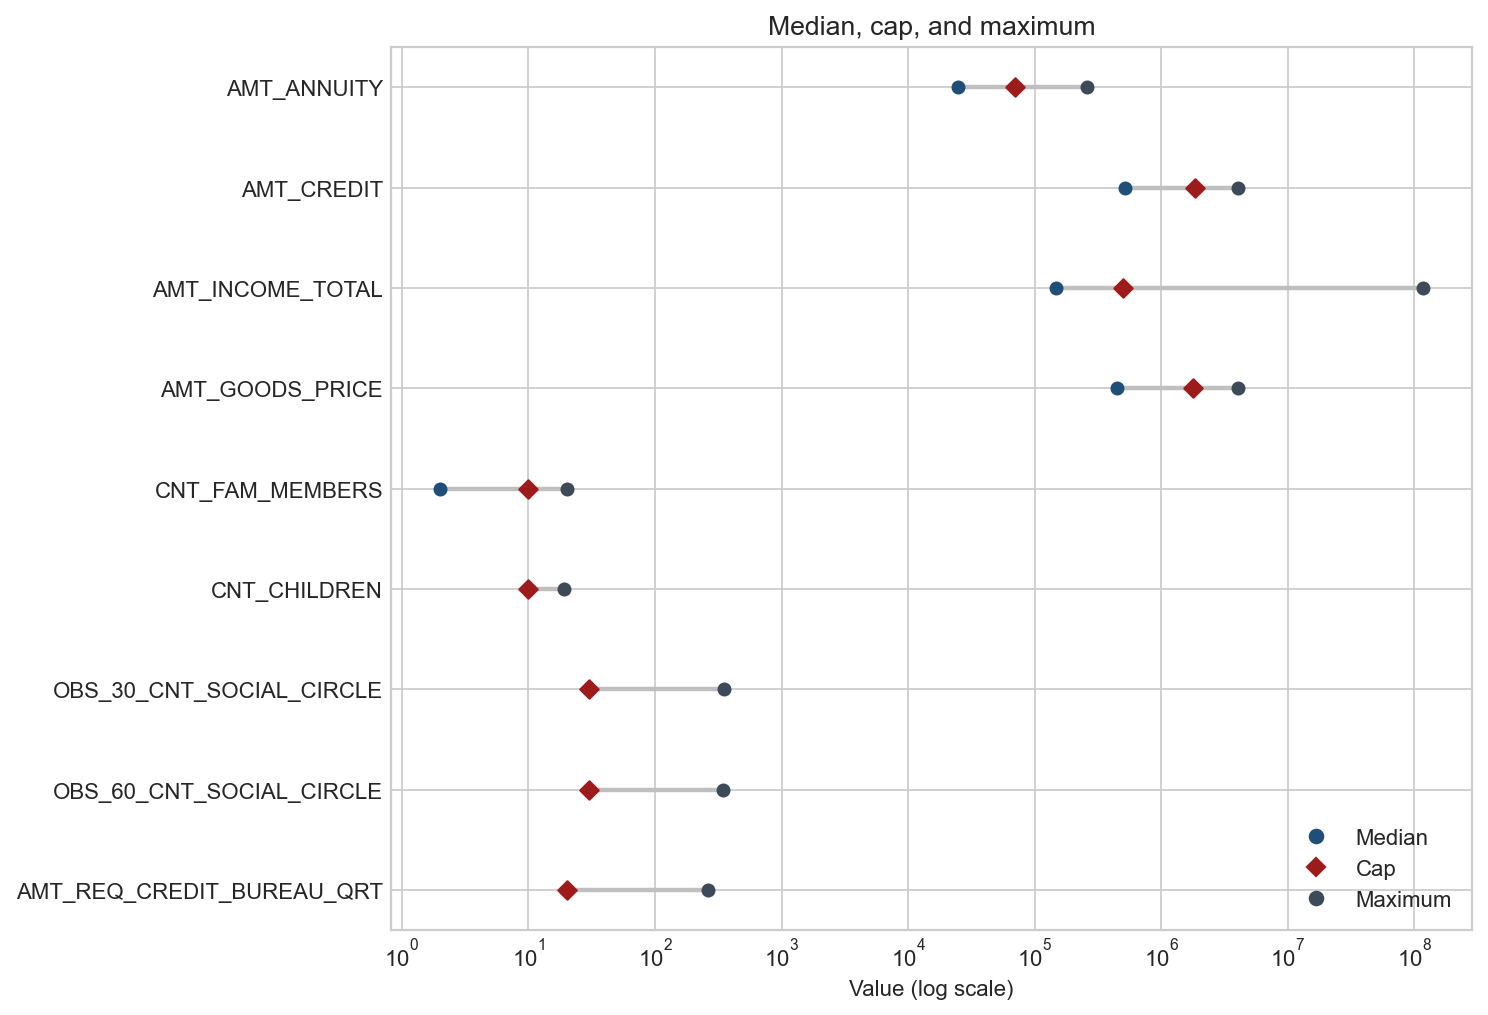

In [315]:
import numpy as np
from matplotlib.lines import Line2D

figure_dir = AUDIT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
tail = prevalence.reset_index(drop=True)
features = tail["feature"].tolist()
positions = np.arange(len(features))
figure, axis = plt.subplots(figsize=(9.4, 0.55 * len(features) + 1.5))
for position, row in zip(positions, tail.itertuples(index=False)):
    start = row.median if row.median > 0 else row.cap
    axis.plot([start, row.maximum], [position, position], color="0.75", linewidth=2, zorder=1)
    if row.median > 0:
        axis.scatter([row.median], [position], s=28, color="#1f4e79", zorder=3)
    axis.scatter([row.cap], [position], s=34, marker="D", color="#9E1B1B", zorder=3)
    axis.scatter([row.maximum], [position], s=28, color="#3C4A59", zorder=3)
axis.set_yticks(positions, features)
axis.invert_yaxis()
axis.set_xscale("log")
axis.set_xlabel("Value (log scale)")
axis.set_title("Median, cap, and maximum")
axis.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#1f4e79", markeredgecolor="#1f4e79", markersize=6, label="Median"),
        Line2D([0], [0], marker="D", color="none", markerfacecolor="#9E1B1B", markeredgecolor="#9E1B1B", markersize=6, label="Cap"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#3C4A59", markeredgecolor="#3C4A59", markersize=6, label="Maximum"),
    ],
    frameon=False,
    loc="lower right",
)
figure.tight_layout()
figure.savefig(figure_dir / "cap_tail.png", dpi=160, bbox_inches="tight")
plt.show()


### 3.2 Demographic Outlier Disparities

This subsection checks whether values above the cap are concentrated in a particular gender, age band, or income band.

The caps are the same training monetary caps and the same fixed caps as in Section 3.1. Within a group, the capping rate uses observed values only:

$$
\text{percent exceeding in a group}
= 100 \times \frac{\text{number above the cap in the group}}{\text{number observed in the group}}.
$$

A group with more missing data is not treated as having more outliers.

Gender is Female or Male. The gender gap is the male rate minus the female rate, in percentage points. Age bands use the same cuts as the rest of this audit: under 25, 25–34, 35–44, 45–54, 55–64, and 65+. Income bands are Q1 low, Q2, Q3, and Q4 high, with cuts from `AMT_INCOME_TOTAL` on the modeling sample used in this section. For age and for income, the gap is the highest group rate minus the lowest group rate. The tables report the rate in each group and that gap.

A larger rate means the capped tail sits more heavily in that group. It describes where the extreme values are. It does not, by itself, say that the cap treats the group unfairly.


In [316]:
from IPython.display import HTML

def group_capping_table(frame, group_column, group_order):
    rows = []
    for feature, cap in feature_caps.items():
        for group in group_order:
            counts = capping_counts(frame.loc[frame[group_column].eq(group), feature], cap)
            rows.append({
                "feature": feature,
                "group": group,
                "n_nonmissing": counts["n_nonmissing"],
                "n_exceeding": counts["n_exceeding"],
                "pct_exceeding": counts["pct_exceeding"],
            })
    return pd.DataFrame(rows)

def show_merged_group_table(frame, title):
    shown = frame.copy()
    for column in ["pct_exceeding", "max_difference_pct"]:
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:.2f}%")
    columns = list(shown.columns)
    merge_columns = ["feature", "max_difference_pct"]
    features = shown["feature"].tolist()
    spans = []
    start = 0
    while start < len(features):
        end = start + 1
        while end < len(features) and features[end] == features[start]:
            end += 1
        spans.append(end - start)
        start = end
    html = [f"<b>{title}</b><table border='1' class='dataframe'><thead><tr>"]
    html.extend(f"<th>{column}</th>" for column in columns)
    html.append("</tr></thead><tbody>")
    row_index = 0
    for span in spans:
        for offset in range(span):
            html.append("<tr>")
            for column in columns:
                if column in merge_columns:
                    if offset == 0:
                        html.append(
                            f"<td rowspan='{span}' style='vertical-align: middle'>{shown.iloc[row_index][column]}</td>"
                        )
                else:
                    html.append(f"<td>{shown.iloc[row_index][column]}</td>")
            html.append("</tr>")
            row_index += 1
    html.append("</tbody></table>")
    display(HTML("".join(html)))

gender_long = group_capping_table(audit, "gender", ["Female", "Male"])
gender_wide = gender_long.pivot(index="feature", columns="group")
gender_summary = pd.DataFrame({
    "feature": gender_wide.index,
    "female_n": gender_wide[("n_nonmissing", "Female")].to_numpy(),
    "female_n_exceeding": gender_wide[("n_exceeding", "Female")].to_numpy(),
    "female_pct": gender_wide[("pct_exceeding", "Female")].to_numpy(),
    "male_n": gender_wide[("n_nonmissing", "Male")].to_numpy(),
    "male_n_exceeding": gender_wide[("n_exceeding", "Male")].to_numpy(),
    "male_pct": gender_wide[("pct_exceeding", "Male")].to_numpy(),
})
gender_summary["difference_pct"] = gender_summary["male_pct"] - gender_summary["female_pct"]
for column in ["female_n", "female_n_exceeding", "male_n", "male_n_exceeding"]:
    gender_summary[column] = gender_summary[column].astype(int)
gender_summary = gender_summary.merge(
    prevalence[["feature", "pct_exceeding"]], on="feature", how="left"
).sort_values("pct_exceeding", ascending=False).drop(columns="pct_exceeding")
gender_summary.to_csv(AUDIT_DIR / "capping_by_gender.csv", index=False)
show_table(
    gender_summary,
    "CAPPING RATES BY GENDER",
    ["female_pct", "male_pct", "difference_pct"],
)

feature,female_n,female_n_exceeding,female_pct,male_n,male_n_exceeding,male_pct,difference_pct
AMT_ANNUITY,202439,1766,0.87%,105054,1319,1.26%,0.38%
AMT_CREDIT,202447,1833,0.91%,105058,1211,1.15%,0.25%
AMT_INCOME_TOTAL,202447,1193,0.59%,105058,1514,1.44%,0.85%
AMT_GOODS_PRICE,202259,788,0.39%,104970,643,0.61%,0.22%
CNT_FAM_MEMBERS,202447,8,0.00%,105058,3,0.00%,-0.00%
CNT_CHILDREN,202447,6,0.00%,105058,2,0.00%,-0.00%
OBS_30_CNT_SOCIAL_CIRCLE,201792,0,0.00%,104692,2,0.00%,0.00%
OBS_60_CNT_SOCIAL_CIRCLE,201792,0,0.00%,104692,2,0.00%,0.00%
AMT_REQ_CREDIT_BUREAU_QRT,176263,1,0.00%,89724,0,0.00%,-0.00%


In [317]:
age_long = group_capping_table(audit, "age_band", AGE_LABELS)
age_long["max_difference_pct"] = age_long.groupby("feature")["pct_exceeding"].transform("max")
age_long.to_csv(AUDIT_DIR / "capping_by_age.csv", index=False)
show_merged_group_table(age_long, "CAPPING RATES BY AGE GROUP")

In [318]:
INCOME_LABELS = ["Q1 low", "Q2", "Q3", "Q4 high"]
income_quartiles = audit["AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75]).to_numpy()
audit["income_band"] = pd.cut(
    audit["AMT_INCOME_TOTAL"],
    bins=[-np.inf, *income_quartiles, np.inf],
    labels=INCOME_LABELS,
    include_lowest=True,
).astype("string")
income_long = group_capping_table(audit, "income_band", INCOME_LABELS)
income_long["max_difference_pct"] = income_long.groupby("feature")["pct_exceeding"].transform("max")
income_long.to_csv(AUDIT_DIR / "capping_by_income.csv", index=False)
show_merged_group_table(income_long, "CAPPING RATES BY INCOME GROUP")

### 3.3 Outliers and Default Outcomes

This subsection compares the observed default rate above each cap with the default rate of the other observed applications.

`TARGET = 1` is a repayment difficulty and `TARGET = 0` is not. For each capped field, the capped group is the observed values strictly above the cap. The comparison group is the other observed values. Missing values are in neither group.

$$
\text{difference}
= 100 \times \left(\bar y_{\text{capped}} - \bar y_{\text{uncapped}}\right),
$$

where $\bar y$ is the mean of `TARGET` in that group. The difference is in percentage points. A negative difference means applications above the cap default less often than applications at or below the cap.

The table includes all nine capped fields. The figure keeps the four monetary fields. The fixed caps flag only a handful of rows, so a default rate for those rows would be a rate among a few applications. The monetary groups each contain more than a thousand capped applications, and the chart prints that count beside the capped bar.

This is a descriptive association between being above the cap and the recorded outcome. It is not an estimate of what the default rate would have been if the value had been left uncapped.


In [319]:
default_rows = []
for feature, cap in feature_caps.items():
    observed = audit[feature].notna()
    capped_mask = observed & audit[feature].gt(cap)
    uncapped_mask = observed & ~audit[feature].gt(cap)
    capped_rate = float(audit.loc[capped_mask, "TARGET"].mean()) if capped_mask.any() else np.nan
    uncapped_rate = float(audit.loc[uncapped_mask, "TARGET"].mean()) if uncapped_mask.any() else np.nan
    default_rows.append({
        "feature": feature,
        "n_capped": int(capped_mask.sum()),
        "default_rate_capped": 100 * capped_rate if pd.notna(capped_rate) else np.nan,
        "n_uncapped": int(uncapped_mask.sum()),
        "default_rate_uncapped": 100 * uncapped_rate if pd.notna(uncapped_rate) else np.nan,
        "difference_pct": 100 * (capped_rate - uncapped_rate) if pd.notna(capped_rate) else np.nan,
    })
default_comparison = pd.DataFrame(default_rows).merge(
    prevalence[["feature", "pct_exceeding"]], on="feature", how="left"
).sort_values("pct_exceeding", ascending=False).drop(columns="pct_exceeding")
default_comparison.to_csv(AUDIT_DIR / "default_rates_by_cap.csv", index=False)
show_table(
    default_comparison,
    "DEFAULT RATES BY CAP STATUS",
    ["default_rate_capped", "default_rate_uncapped", "difference_pct"],
)

feature,n_capped,default_rate_capped,n_uncapped,default_rate_uncapped,difference_pct
AMT_ANNUITY,3085,3.82%,304408,8.12%,-4.29%
AMT_CREDIT,3044,4.07%,304461,8.11%,-4.04%
AMT_INCOME_TOTAL,2707,5.43%,304798,8.10%,-2.67%
AMT_GOODS_PRICE,1431,3.42%,305798,8.10%,-4.67%
CNT_FAM_MEMBERS,11,18.18%,307494,8.07%,10.11%
CNT_CHILDREN,8,12.50%,307497,8.07%,4.43%
OBS_30_CNT_SOCIAL_CIRCLE,2,0.00%,306482,8.09%,-8.09%
OBS_60_CNT_SOCIAL_CIRCLE,2,0.00%,306482,8.09%,-8.09%
AMT_REQ_CREDIT_BUREAU_QRT,1,0.00%,265986,7.72%,-7.72%


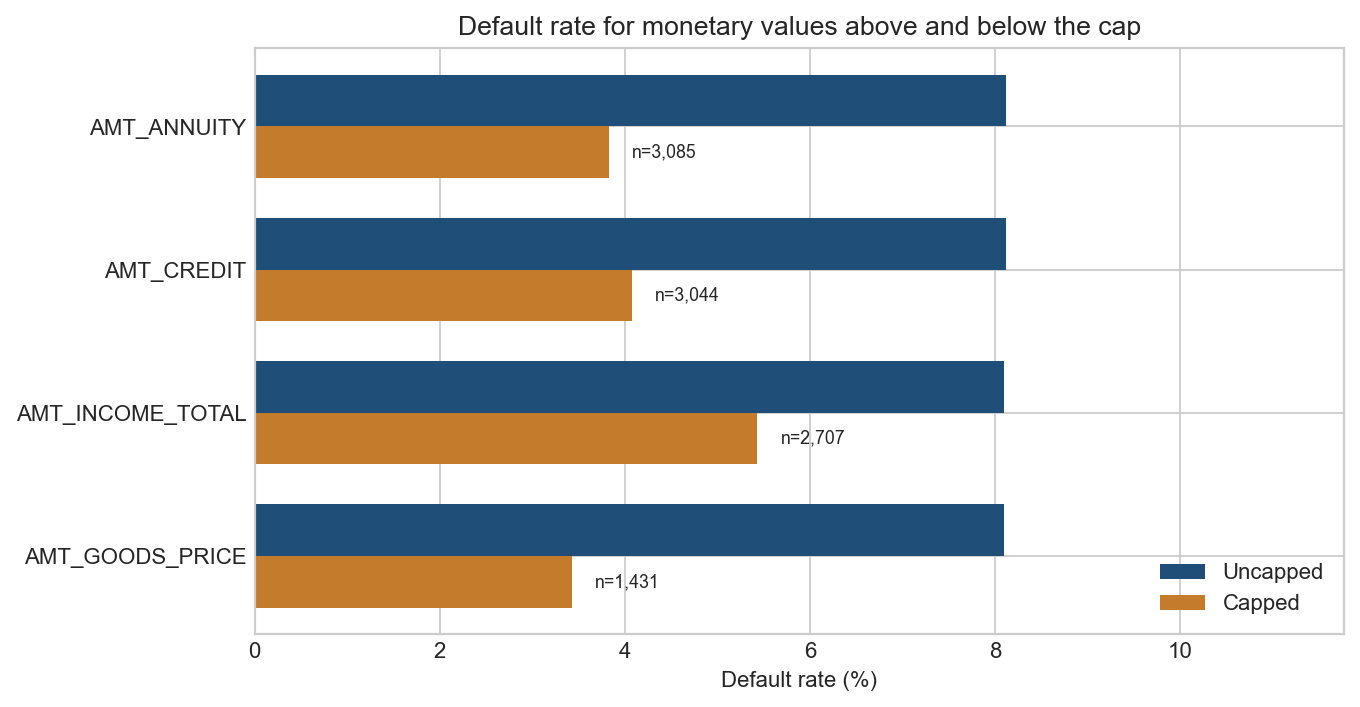

In [320]:
import numpy as np

figure_dir = AUDIT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
monetary = default_comparison[default_comparison["feature"].isin(MONETARY_FEATURES)].reset_index(drop=True)
features = monetary["feature"].tolist()
positions = np.arange(len(features))
height = 0.36
figure, axis = plt.subplots(figsize=(8.6, 0.78 * len(features) + 1.4))
axis.barh(positions - height / 2, monetary["default_rate_uncapped"], height=height, color="#1f4e79", label="Uncapped")
axis.barh(positions + height / 2, monetary["default_rate_capped"], height=height, color="#c47b2b", label="Capped")
for position, row in zip(positions, monetary.itertuples(index=False)):
    axis.text(row.default_rate_capped + 0.25, position + height / 2, f"n={row.n_capped:,}", va="center", fontsize=8)
axis.set_yticks(positions, features)
axis.invert_yaxis()
axis.set_xlim(0, max(monetary["default_rate_uncapped"].max(), monetary["default_rate_capped"].max()) * 1.45)
axis.set_xlabel("Default rate (%)")
axis.set_title("Default rate for monetary values above and below the cap")
axis.legend(frameon=False, loc="lower right")
figure.tight_layout()
figure.savefig(figure_dir / "default_rates_by_cap.png", dpi=160, bbox_inches="tight")
plt.show()


### 3.4 Synthetic Ratio If Winsorisation Applied

This subsection checks whether an extreme monetary value can still reach the model after that value is winsorized.

The training pipeline builds four ratios from the raw monetary fields, and it builds them before the 99th-percentile cap is applied. The ratios themselves are not in the winsorization step:

$$
\begin{aligned}
\text{CREDIT\_INCOME\_RATIO} &= \texttt{AMT\_CREDIT} / \texttt{AMT\_INCOME\_TOTAL}, \\
\text{ANNUITY\_INCOME\_RATIO} &= \texttt{AMT\_ANNUITY} / \texttt{AMT\_INCOME\_TOTAL}, \\
\text{CREDIT\_TERM} &= \texttt{AMT\_CREDIT} / \texttt{AMT\_ANNUITY}, \\
\text{CREDIT\_GOODS\_RATIO} &= \texttt{AMT\_CREDIT} / \texttt{AMT\_GOODS\_PRICE}.
\end{aligned}
$$

An income of 117 million, for example, is later capped, but a ratio that was divided by the uncapped income keeps the extreme value.

This check recomputes each ratio after clipping the monetary inputs at the training caps, then counts how many defined ratios would change. A ratio is defined when both the raw value and the capped-input value are finite. It counts as changed when those two values differ by more than $10^{-8}$. The table reports how many ratios are defined, how many would change, the percent that would change, and the largest absolute change. The pipeline used to train the models is left as it is.


In [321]:
capped_inputs = {feature: audit[feature].clip(upper=cap) for feature, cap in winsor_caps.items()}
raw_ratios = {
    "CREDIT_INCOME_RATIO": audit["AMT_CREDIT"] / audit["AMT_INCOME_TOTAL"],
    "ANNUITY_INCOME_RATIO": audit["AMT_ANNUITY"] / audit["AMT_INCOME_TOTAL"],
    "CREDIT_TERM": audit["AMT_CREDIT"] / audit["AMT_ANNUITY"],
    "CREDIT_GOODS_RATIO": audit["AMT_CREDIT"] / audit["AMT_GOODS_PRICE"],
}
capped_ratios = {
    "CREDIT_INCOME_RATIO": capped_inputs["AMT_CREDIT"] / capped_inputs["AMT_INCOME_TOTAL"],
    "ANNUITY_INCOME_RATIO": capped_inputs["AMT_ANNUITY"] / capped_inputs["AMT_INCOME_TOTAL"],
    "CREDIT_TERM": capped_inputs["AMT_CREDIT"] / capped_inputs["AMT_ANNUITY"],
    "CREDIT_GOODS_RATIO": capped_inputs["AMT_CREDIT"] / capped_inputs["AMT_GOODS_PRICE"],
}
ratio_rows = []
for ratio_name in raw_ratios:
    raw_values = raw_ratios[ratio_name].replace([np.inf, -np.inf], np.nan)
    capped_values = capped_ratios[ratio_name].replace([np.inf, -np.inf], np.nan)
    defined = raw_values.notna() & capped_values.notna()
    changed = defined & ~np.isclose(raw_values, capped_values, rtol=0, atol=1e-8)
    ratio_rows.append({
        "ratio": ratio_name,
        "n_defined": int(defined.sum()),
        "n_changed_if_inputs_capped_first": int(changed.sum()),
        "pct_changed": 100 * changed.sum() / defined.sum(),
        "max_absolute_difference": float((raw_values - capped_values).abs()[changed].max()) if changed.any() else 0.0,
    })
ratio_sensitivity = pd.DataFrame(ratio_rows)
ratio_sensitivity.to_csv(AUDIT_DIR / "ratio_sensitivity_to_caps.csv", index=False)
show_table(
    ratio_sensitivity,
    "RATIO CHANGE IF INPUTS WERE CAPPED FIRST",
    ["pct_changed"],
)

ratio,n_defined,n_changed_if_inputs_capped_first,pct_changed,max_absolute_difference
CREDIT_INCOME_RATIO,307505,5397,1.76%,11.95
ANNUITY_INCOME_RATIO,307493,5451,1.77%,0.69
CREDIT_TERM,307493,5354,1.74%,16.71
CREDIT_GOODS_RATIO,307229,3084,1.00%,0.16


## 4. Train/Validation/Test Representation

This section compares gender, age, and income across the training, validation, and test sets: whether each group has a similar share in the three sets, and whether its default rate is similar as well.

The split is the original modeling split. The models are not retrained, the split is not redrawn, and the sample is not rebalanced. Applications with `CODE_GENDER = XNA` or `NAME_FAMILY_STATUS = Unknown` are removed first. The remaining 307,505 applications are split 70% / 15% / 15%, stratified on `TARGET`, with seed 42:

| Split | Applications |
| --- | ---: |
| Training | 215,253 |
| Validation | 46,126 |
| Test | 46,126 |

Gender is Female or Male. Age bands use the same cuts as the rest of this audit. Income quartiles are calculated once, on the training applicants only, and those same cut points are applied to validation and test. An income that falls on a boundary goes into the lower band.

Stratification keeps the overall default rate aligned across the three splits. It does not force each gender, age band, or income band to have the same share, or the same default rate, in every split. The two subsections describe those remaining differences.


### 4.1 Demographic Representation Across Splits

This subsection compares the gender, age, and income mixes in training, validation, and test.

For a group $g$ and a split $s$, the table reports the percent of that split who belong to the group:

$$
p_{g,s} = 100 \times \frac{\text{number of applications in group } g \text{ and split } s}{\text{number of applications in split } s}.
$$

The columns of each table therefore sum to 100% within a split. The last column is the largest share minus the smallest share across the three splits, in percentage points:

$$
\text{max diff} = \max_s p_{g,s} - \min_s p_{g,s}.
$$

A max diff near zero means the group's share is almost the same in training, validation, and test. There is one table for gender, one for age, and one for income.


In [322]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
SPLIT_DIR = Path("output") / "audit" / "split_representation"
SPLIT_FIG = SPLIT_DIR / "figures"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_FIG.mkdir(parents=True, exist_ok=True)

AGE_LABELS = ["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
INCOME_LABELS = ["Q1 low", "Q2", "Q3", "Q4 high"]
SPLIT_ORDER = ["Training", "Validation", "Test"]
SPLIT_COLORS = {"Training": "#4c78a8", "Validation": "#f58518", "Test": "#54a24b"}

split_df = (
    df.loc[~df["CODE_GENDER"].eq("XNA") & ~df["NAME_FAMILY_STATUS"].eq("Unknown")]
    .reset_index(drop=True)
)
y_split = split_df["TARGET"]
row_index = split_df.index.to_numpy()
idx_train, idx_temp, y_train, y_temp = train_test_split(
    row_index, y_split, test_size=0.30, stratify=y_split, random_state=SEED
)
idx_val, idx_test, _, _ = train_test_split(
    idx_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
assert len(split_df) == 307_505
assert (len(idx_train), len(idx_val), len(idx_test)) == (215_253, 46_126, 46_126)

split_df["gender"] = split_df["CODE_GENDER"].map({"F": "Female", "M": "Male"})
split_df["age_band"] = pd.cut(
    -split_df["DAYS_BIRTH"] / 365.25,
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=AGE_LABELS,
    right=False,
).astype("string")
income_quartiles = split_df.loc[idx_train, "AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75])
split_df["income_band"] = pd.cut(
    split_df["AMT_INCOME_TOTAL"],
    bins=[-np.inf, *income_quartiles.to_numpy(), np.inf],
    labels=INCOME_LABELS,
    include_lowest=True,
).astype("string")
split_df["split"] = "Validation"
split_df.loc[idx_train, "split"] = "Training"
split_df.loc[idx_test, "split"] = "Test"
assert split_df["gender"].notna().all()
assert split_df["age_band"].notna().all()
assert split_df["income_band"].notna().all()

def representation_table(column, group_order):
    counts = (
        pd.crosstab(split_df[column], split_df["split"])
        .reindex(index=group_order, columns=SPLIT_ORDER)
    )
    proportions = counts.div(counts.sum(axis=0), axis=1) * 100
    table = pd.DataFrame({"group": group_order})
    for split_name in SPLIT_ORDER:
        table[f"{split_name.lower()}_pct"] = proportions[split_name].to_numpy()
    table["max_diff_pp"] = proportions.max(axis=1).to_numpy() - proportions.min(axis=1).to_numpy()
    return table

gender_representation = representation_table("gender", ["Female", "Male"])
age_representation = representation_table("age_band", AGE_LABELS)
income_representation = representation_table("income_band", INCOME_LABELS)
gender_representation.to_csv(SPLIT_DIR / "representation_by_gender.csv", index=False)
age_representation.to_csv(SPLIT_DIR / "representation_by_age.csv", index=False)
income_representation.to_csv(SPLIT_DIR / "representation_by_income.csv", index=False)

def show_table(frame, title, percent_columns):
    shown = frame.copy()
    for column in percent_columns:
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:.2f}%")
    for column in shown.columns:
        if column in percent_columns or shown[column].dtype == object:
            continue
        if pd.api.types.is_integer_dtype(shown[column]):
            continue
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:,.2f}")
    display(HTML(f"<b>{title}</b>" + shown.to_html(index=False)))

from IPython.display import HTML
percent_cols = ["training_pct", "validation_pct", "test_pct", "max_diff_pp"]
show_table(gender_representation, "GENDER REPRESENTATION BY SPLIT", percent_cols)
show_table(age_representation, "AGE REPRESENTATION BY SPLIT", percent_cols)
show_table(income_representation, "INCOME REPRESENTATION BY SPLIT", percent_cols)

group,training_pct,validation_pct,test_pct,max_diff_pp
Female,65.83%,65.75%,65.93%,0.18%
Male,34.17%,34.25%,34.07%,0.18%


group,training_pct,validation_pct,test_pct,max_diff_pp
Under 25,3.97%,3.99%,4.01%,0.04%
25–34,23.54%,23.83%,23.33%,0.49%
35–44,27.42%,27.09%,27.60%,0.51%
45–54,22.83%,22.68%,22.94%,0.26%
55–64,19.69%,19.84%,19.50%,0.34%
65+,2.55%,2.58%,2.62%,0.07%


group,training_pct,validation_pct,test_pct,max_diff_pp
Q1 low,32.76%,32.38%,32.79%,0.41%
Q2,17.27%,17.35%,17.08%,0.27%
Q3,26.66%,27.07%,27.02%,0.41%
Q4 high,23.31%,23.21%,23.11%,0.19%


### 4.2 Default-Rate Representation

This subsection compares, within each demographic group, the observed default rate in training, validation, and test.

The split was stratified on `TARGET` for the whole sample. It was not stratified inside gender, age, or income, so a group's default rate can differ across splits even when the overall default rate does not.

For a group $g$ and a split $s$,

$$
\text{default rate}_{g,s}
= 100 \times \frac{\text{number of defaults in group } g \text{ and split } s}{\text{number of applications in group } g \text{ and split } s}.
$$

`max_diff_pp` is the largest of those three rates minus the smallest, in percentage points. The first table is the overall default rate in each split, which is the rate the stratification was built to keep stable. The next tables break that rate out by gender, by age, and by income.

A larger max diff means that group's outcome mix is less alike across the three sets. It describes the split. It is not, by itself, evidence that the model treats the group differently.


In [323]:
def default_by_group(column, group_order):
    rows = []
    for group in group_order:
        rates = []
        row = {"group": group}
        for split_name in SPLIT_ORDER:
            part = split_df.loc[split_df[column].eq(group) & split_df["split"].eq(split_name), "TARGET"]
            rate = 100 * float(part.mean()) if len(part) else np.nan
            row[f"{split_name.lower()}_default_pct"] = rate
            rates.append(rate)
        row["max_diff_pp"] = max(rates) - min(rates)
        rows.append(row)
    return pd.DataFrame(rows)

overall_rows = []
for split_name in SPLIT_ORDER:
    part = split_df.loc[split_df["split"].eq(split_name), "TARGET"]
    overall_rows.append({
        "split": split_name,
        "default_pct": 100 * float(part.mean()),
    })
overall_default = pd.DataFrame(overall_rows)
gender_default = default_by_group("gender", ["Female", "Male"])
age_default = default_by_group("age_band", AGE_LABELS)
income_default = default_by_group("income_band", INCOME_LABELS)
overall_default.to_csv(SPLIT_DIR / "overall_default_by_split.csv", index=False)
gender_default.to_csv(SPLIT_DIR / "default_rates_by_gender.csv", index=False)
age_default.to_csv(SPLIT_DIR / "default_rates_by_age.csv", index=False)
income_default.to_csv(SPLIT_DIR / "default_rates_by_income.csv", index=False)

rate_cols = ["training_default_pct", "validation_default_pct", "test_default_pct", "max_diff_pp"]
show_table(overall_default, "OVERALL DEFAULT RATE BY SPLIT", ["default_pct"])
show_table(gender_default, "DEFAULT RATES BY GENDER AND SPLIT", rate_cols)
show_table(age_default, "DEFAULT RATES BY AGE AND SPLIT", rate_cols)
show_table(income_default, "DEFAULT RATES BY INCOME AND SPLIT", rate_cols)

split,default_pct
Training,8.07%
Validation,8.07%
Test,8.07%


group,training_default_pct,validation_default_pct,test_default_pct,max_diff_pp
Female,6.99%,7.01%,7.02%,0.03%
Male,10.16%,10.11%,10.10%,0.05%


group,training_default_pct,validation_default_pct,test_default_pct,max_diff_pp
Under 25,12.43%,11.58%,12.38%,0.85%
25–34,10.71%,10.60%,10.51%,0.20%
35–44,8.42%,8.52%,8.24%,0.28%
45–54,6.98%,6.97%,7.45%,0.48%
55–64,5.39%,5.63%,5.34%,0.29%
65+,3.70%,3.20%,3.89%,0.69%


group,training_default_pct,validation_default_pct,test_default_pct,max_diff_pp
Q1 low,8.42%,8.44%,8.21%,0.24%
Q2,8.55%,8.24%,8.73%,0.50%
Q3,8.44%,8.15%,8.45%,0.30%
Q4 high,6.81%,7.34%,6.96%,0.54%
